# St. Lucia 2023 Article IV (IMF Country Report No. 24/68): LLM extraction, RAG and dashboard pipeline

The notebook reads the IMF staff report, summarises and audits it with two Gemini models, extracts the indicator JSON and trend series, answers questions through a FAISS retriever, benchmarks model and instruction choices, and draws the dashboard. *Runtime > Run all* replays every model answer from `cache/llm_cache.sqlite`, so a rerun needs no key and gives the numbers in the report.

> **Why this way:** the code is organised as small classes (`LLMGateway`, `GlyphRepair`, `PageCleaner`, one function per chart), so each stage can be tested and rerun on its own, and every model call passes through one cached gateway.

## Part 0 · Setup

In [1]:
# Colab already has pandas, matplotlib, tokenizers and sentence-transformers. pypdf is pinned
# because a different version extracts slightly different text, which would change every prompt
# and so every cache key. faiss-cpu is not preinstalled in Colab.
import subprocess
import sys

RUNNING_IN_COLAB = "google.colab" in sys.modules
# pypdfium2 renders pages for OCR; tesseract is the OCR engine (see Task 1.2).
if RUNNING_IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pypdf==6.21.4", "pypdfium2==5.14.0", "faiss-cpu==1.15.1"], check=True)
    subprocess.run(["apt-get", "install", "-y", "-qq", "tesseract-ocr"], check=False, capture_output=True)

from importlib.metadata import version
print({pkg: version(pkg) for pkg in ("pypdf", "pypdfium2", "tokenizers", "pydantic", "pandas")})

{'pypdf': '6.21.4', 'pypdfium2': '5.14.0', 'tokenizers': '0.23.3', 'pydantic': '2.14.1', 'pandas': '2.2.3'}


### Run settings and folders
> **Why this way:** every setting the pipeline uses sits in one `RunSettings` object, so no later cell hardcodes a path, a model name or a threshold. Paths are relative to the repository, which keeps the notebook portable between Colab and a laptop.

In [2]:
import difflib
import hashlib
import json
import os
import re
import shutil
import sqlite3
import tempfile
import time
import unicodedata
import warnings
from collections import Counter
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from types import SimpleNamespace
from typing import Literal, Optional

# Quiet two harmless library notices (progress-bar widget, anonymous model download) that would
# otherwise print install paths into the saved notebook.
os.environ.setdefault("HF_HUB_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
from pydantic import BaseModel, Field, ValidationError
from pypdf import PdfReader
from tokenizers import Tokenizer


@dataclass(frozen=True)
class RunSettings:
    """Every knob of the pipeline in one place. Nothing below this cell hardcodes a value."""
    country: str = "St. Lucia"
    # Allocation: St. Lucia, 2023-2024. Read as "published in 2023-2024", like the brief's example
    # (UK 2024-2025 -> report issued in 2025). St. Lucia's only Staff Report / Article IV issued in
    # that window is CR 24/68 (2023 consultation, published 8 March 2024). The 2024 consultation
    # (CR 25/65) was published in March 2025, outside the window; swap pdf_name/pdf_url to use it
    # if the period is read as consultation year instead.
    report_id: str = "IMF Country Report No. 24/68 (March 2024)"
    report_title: str = "St. Lucia: 2023 Article IV Consultation - Press Release; and Staff Report"
    pdf_name: str = "stlucia_cr2468.pdf"
    pdf_url: str = ("https://www.elibrary.imf.org/downloadpdf/view/journals/002/2024/068/"
                    "002.2024.issue-068-en.pdf")
    repo_url: str = ""                       # GitHub URL, lets Colab fetch data/ and cache/
    # Where uncached calls go: "auto" picks colab inside Colab, then gemini_api if a key is set,
    # then the Antigravity CLI ("agy") if installed, otherwise "replay" (cache only).
    backend: str = os.environ.get("IMF_LLM_BACKEND", "auto")   # e.g. IMF_LLM_BACKEND=replay forbids live calls
    # Writer and judge are different models on purpose, so the judge never grades its own text; the
    # judge is a larger tier than the Flash writer (Pro in Colab, Argon in Antigravity). Both are
    # Gemini, so some same-family preference may remain: that is why every judge score sits next to
    # code checks (number grounding, quote matching).
    models: dict = field(default_factory=lambda: {
        "colab":      {"writer": "google/gemini-3.8-flash", "judge": "google/gemini-3.1-pro-preview"},
        "gemini_api": {"writer": "gemini-3.8-flash", "judge": "gemini-3.8-pro"},
        "agy":        {"writer": "gemini-3.8-flash-medium", "judge": "gemini-4-argon-medium"},
    })
    # Extension: three writer variants raced on the same extraction inputs. The judge model is kept
    # out of this list so it never grades its own answers. Antigravity offers Gemini 3.8 Flash at
    # three thinking budgets; Colab and the API use the Flash variants named in the brief.
    bench_models: dict = field(default_factory=lambda: {
        "colab":      {"bench_a": "google/gemini-3.5-flash-lite", "bench_b": "google/gemini-3.5-flash",
                       "bench_c": "google/gemini-3.8-flash"},
        "gemini_api": {"bench_a": "gemini-3.5-flash-lite", "bench_b": "gemini-3.5-flash", "bench_c": "gemini-3.8-flash"},
        "agy":        {"bench_a": "gemini-3.8-flash-low", "bench_b": "gemini-3.8-flash-medium",
                       "bench_c": "gemini-3.8-flash-high"},
    })
    max_attempts: int = 4
    # Chunks are measured with the embedding model's own tokenizer. bge-small reads at most
    # 512 tokens, so a 400-token ceiling (header included) keeps every chunk fully visible to the
    # retriever. Most chunks land in the brief's 300-500 band; tables and section tails can be shorter.
    tokenizer_name: str = "BAAI/bge-small-en-v1.5"
    embed_model: str = "BAAI/bge-small-en-v1.5"   # same model as the tokenizer, so chunk limits match
    chunk_tokens: int = 400
    chunk_overlap: int = 50
    summary_word_cap: int = 100              # brief: each section summary under 100 words
    summary_word_target: int = 80
    min_section_words: int = 40              # smaller bookmark sections fold into the next one


CFG = RunSettings()

ROOT = Path.cwd()
if RUNNING_IN_COLAB and CFG.repo_url and not (ROOT / "data").exists():
    subprocess.run(["git", "clone", "-q", CFG.repo_url, "repo"], check=True)
    os.chdir("repo")
    ROOT = Path.cwd()

DIRS = SimpleNamespace(data=ROOT / "data", cache=ROOT / "cache",
                       json=ROOT / "artifacts" / "json", figures=ROOT / "artifacts" / "figures")
for folder in vars(DIRS).values():
    folder.mkdir(parents=True, exist_ok=True)


def dump_json(name: str, payload) -> Path:
    """Write one machine-readable artifact to artifacts/json/."""
    target = DIRS.json / name
    target.write_text(json.dumps(payload, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
    return target


print("Project folder:", ROOT.name)

Project folder: content


### LLM gateway with a SQLite answer cache
> **Why this way:** one class is the only door to a model. It checks the cache first, validates JSON replies against a Pydantic schema and asks once for a repair, retries transient errors with backoff, and in replay mode refuses any live call. The cache makes the run reproducible and free to repeat.

In [3]:
def flatten_schema(model_cls) -> dict:
    """Pydantic JSON schema with every $ref inlined (the CLI and Colab prompt need a flat schema)."""
    raw = model_cls.model_json_schema()
    defs = raw.pop("$defs", {})

    def inline(node):
        if isinstance(node, dict):
            if "$ref" in node:
                return inline(defs[node["$ref"].rsplit("/", 1)[-1]])
            return {k: inline(v) for k, v in node.items()}
        if isinstance(node, list):
            return [inline(v) for v in node]
        return node
    return inline(raw)


def pull_json(reply: str):
    """Read JSON out of a reply that may carry markdown fences or a sentence around it."""
    body = re.sub(r"^```(?:json)?\s*|\s*```$", "", reply.strip())
    try:
        return json.loads(body)
    except json.JSONDecodeError:
        found = re.search(r"\{.*\}|\[.*\]", body, flags=re.S)
        if not found:
            raise
        return json.loads(found.group(0))


class CacheMiss(RuntimeError):
    """Raised in replay mode when an answer was never recorded."""


class LLMGateway:
    """The only door to a model. It
    - chooses a backend once (Colab built-in Gemini, Gemini API, Antigravity CLI, or replay),
    - stores every answer in one SQLite file keyed by a BLAKE2 hash of model + system + prompt +
      schema, so rerunning the notebook costs no quota and gives identical numbers,
    - retries with growing pauses, and logs latency for each call (used by the extension),
    - validates JSON replies against a Pydantic schema and asks once for a repair if they fail."""

    def __init__(self, settings: RunSettings, db_path: Path):
        self.cfg = settings
        self.db = sqlite3.connect(db_path)
        self.db.execute("CREATE TABLE IF NOT EXISTS answers (key TEXT PRIMARY KEY, role TEXT, model TEXT,"
                        " backend TEXT, created TEXT, latency_s REAL, prompt_chars INTEGER, reply TEXT)")
        self.db.execute("CREATE TABLE IF NOT EXISTS run_meta (name TEXT PRIMARY KEY, value TEXT)")
        self.backend = self._choose_backend()
        self.models, self.live_models = self._choose_models()
        self.ledger: list[dict] = []
        self._sandbox = Path(tempfile.mkdtemp(prefix="agy_blank_"))   # nothing here for the CLI agent to read

    def _choose_backend(self) -> str:
        if self.cfg.backend != "auto":
            return self.cfg.backend
        if RUNNING_IN_COLAB:
            return "colab"
        if self._api_key():
            return "gemini_api"
        return "agy" if shutil.which("agy") else "replay"

    def _choose_models(self) -> tuple[dict, dict]:
        """Cache first. If the shipped cache records which models produced it, those names are used for
        every lookup, whatever backend this machine has, so a marker's rerun replays the exact answers
        behind the report with zero live calls. Only a genuine miss goes live, through this backend's
        own models (a model name from another backend would not exist there)."""
        recorded = self.db.execute("SELECT value FROM run_meta WHERE name='models'").fetchone()
        if self.backend == "replay":
            if not recorded:
                raise CacheMiss("Replay mode needs cache/llm_cache.sqlite from a previous run.")
            return json.loads(recorded[0]), {}
        live = {**self.cfg.models[self.backend], **self.cfg.bench_models[self.backend]}
        if live["writer"] == live["judge"]:
            raise ValueError("Writer and judge must be different models.")
        if recorded:
            cached = json.loads(recorded[0])
            added = {role: name for role, name in live.items() if role not in cached}
            if added:       # roles introduced after this cache was started (the benchmark variants)
                cached.update(added)
                self.db.execute("UPDATE run_meta SET value=? WHERE name='models'", (json.dumps(cached),))
                self.db.commit()
            if cached != live:
                print(f"Replaying the cache made by {cached}; any uncached call goes live on {live}.")
            return cached, live
        self.db.execute("INSERT OR REPLACE INTO run_meta VALUES ('models', ?)", (json.dumps(live),))
        self.db.commit()
        return dict(live), live

    def _key(self, model, system, prompt, schema_json) -> str:
        return hashlib.blake2b(json.dumps([model, system, prompt, schema_json], sort_keys=True).encode(),
                               digest_size=20).hexdigest()

    @staticmethod
    def _api_key() -> Optional[str]:
        if RUNNING_IN_COLAB:
            try:
                from google.colab import userdata
                return userdata.get("GEMINI_API_KEY")
            except Exception:
                return None
        return os.environ.get("GEMINI_API_KEY")

    # one live call per backend; each returns plain text
    def _call_colab(self, model, system, prompt, schema_json):
        from google.colab import ai
        text = (f"SYSTEM INSTRUCTIONS:\n{system}\n\n" if system else "") + prompt
        if schema_json:
            text += "\n\nReply with JSON only, no code fences, valid against this schema:\n" + json.dumps(schema_json)
        return ai.generate_text(text, model_name=model)

    def _call_gemini_api(self, model, system, prompt, schema_cls):
        from google import genai
        from google.genai import types
        client = genai.Client(api_key=self._api_key())
        conf = types.GenerateContentConfig(temperature=0.0, system_instruction=system or None)
        if schema_cls is not None:
            conf.response_mime_type, conf.response_schema = "application/json", schema_cls
        return client.models.generate_content(model=model, contents=prompt, config=conf).text or ""

    def _call_agy(self, model, system, prompt, schema_json):
        text = ((f"SYSTEM INSTRUCTIONS:\n{system}\n\n" if system else "")
                + "Use no tools. Answer only from the text below.\n\n" + prompt)
        cmd = ["agy", "-p", text, "--model", model, "--output-format", "json", "--sandbox",
               "--disable-slash-commands", "--print-timeout", "600s"]
        if schema_json:
            cmd += ["--json-schema", json.dumps(schema_json)]
        done = subprocess.run(cmd, cwd=self._sandbox, capture_output=True, text=True, timeout=720)
        envelope = json.loads(done.stdout)
        if envelope.get("status") != "SUCCESS":
            raise RuntimeError(str(envelope.get("error") or envelope.get("response"))[:300])
        if envelope.get("structured_output") is not None:
            return json.dumps(envelope["structured_output"])
        return envelope["response"]

    def _live(self, model, system, prompt, schema_cls, schema_json):
        last_error = None
        for attempt in range(self.cfg.max_attempts):
            try:
                if self.backend == "colab":
                    return self._call_colab(model, system, prompt, schema_json)
                if self.backend == "gemini_api":
                    return self._call_gemini_api(model, system, prompt, schema_cls)
                return self._call_agy(model, system, prompt, schema_json)
            except Exception as err:            # rate limits and timeouts are worth a second try
                last_error = err
                time.sleep(min(90, 6 * 2 ** attempt))
        raise RuntimeError(f"{self.backend}/{model} failed after {self.cfg.max_attempts} attempts: {last_error}")

    def ask(self, prompt: str, role: str = "writer", system: str = "", schema=None, tag: str = "") -> str:
        schema_json = flatten_schema(schema) if schema is not None else None
        # look up under the cached model first, then under this backend's own model
        for model in dict.fromkeys([self.models.get(role), self.live_models.get(role)]):
            if model is None:
                continue
            key = self._key(model, system, prompt, schema_json)
            hit = self.db.execute("SELECT reply, latency_s FROM answers WHERE key=?", (key,)).fetchone()
            if hit:
                self.ledger.append({"tag": tag, "role": role, "model": model, "cached": True, "latency_s": hit[1]})
                return hit[0]
        if self.backend == "replay":
            raise CacheMiss(f"No cached answer for '{tag}' and no live backend available.")
        model = self.live_models[role]
        key = self._key(model, system, prompt, schema_json)
        started = time.perf_counter()
        reply = self._live(model, system, prompt, schema, schema_json)
        latency = round(time.perf_counter() - started, 2)
        self.db.execute("INSERT INTO answers VALUES (?,?,?,?,?,?,?,?)",
                        (key, role, model, self.backend, datetime.now(timezone.utc).isoformat(),
                         latency, len(prompt), reply))
        self.db.commit()
        self.ledger.append({"tag": tag, "role": role, "model": model, "cached": False, "latency_s": latency})
        return reply

    def ask_json(self, prompt: str, schema, role: str = "writer", system: str = "", tag: str = ""):
        reply = self.ask(prompt, role, system, schema, tag)
        try:
            return schema.model_validate(pull_json(reply))
        except (ValidationError, json.JSONDecodeError) as problem:
            fix = (f"{prompt}\n\nYour earlier reply did not validate.\nError: {str(problem)[:700]}\n"
                   f"Earlier reply: {reply[:3500]}\nSend the corrected JSON only.")
            return schema.model_validate(pull_json(self.ask(fix, role, system, schema, tag + ":repair")))


llm = LLMGateway(CFG, DIRS.cache / "llm_cache.sqlite")
print(f"Backend: {llm.backend} | cached answers from writer {llm.models['writer']}, judge {llm.models['judge']}")

Backend: colab | cached answers from writer google/gemini-3.8-flash, judge google/gemini-3.1-pro-preview


## Part 1 · From PDF to summaries (Task 1)
### Task 1.1 · Load the report
> **Why this way:** the PDF ships in `data/`, so the notebook does not depend on imf.org, which often blocks scripted downloads. A download and, in Colab, an upload box are fallbacks only.

In [4]:
def locate_report(settings: RunSettings) -> Path:
    """Find the PDF in data/ (or next to the notebook); otherwise download it, or ask for an upload in Colab."""
    target = DIRS.data / settings.pdf_name
    beside = ROOT / settings.pdf_name
    if not target.exists() and beside.exists():
        beside.replace(target)
    if target.exists() and target.read_bytes()[:5] == b"%PDF-":
        return target
    try:
        import urllib.request
        request = urllib.request.Request(settings.pdf_url, headers={"User-Agent": "Mozilla/5.0"})
        payload = urllib.request.urlopen(request, timeout=60).read()
        if payload[:5] == b"%PDF-":
            target.write_bytes(payload)
            return target
    except Exception as err:
        print("Automatic download failed (the IMF site often blocks scripts):", err)
    if RUNNING_IN_COLAB:
        from google.colab import files
        print(f"Upload {settings.pdf_name}")
        uploaded = files.upload()
        target.write_bytes(next(iter(uploaded.values())))
        return target
    raise FileNotFoundError(f"Place the report at {target}")


REPORT_PATH = locate_report(CFG)
reader = PdfReader(str(REPORT_PATH))
raw_pages = [page.extract_text() or "" for page in reader.pages]
print(f"{REPORT_PATH.name}: {len(raw_pages)} pages, {sum(map(len, raw_pages)):,} characters, "
      f"sha256 {hashlib.sha256(REPORT_PATH.read_bytes()).hexdigest()[:12]}")

stlucia_cr2468.pdf: 66 pages, 131,466 characters, sha256 98bee5a6a32d


### Task 1.2 · Repair letters the PDF fonts lost, using OCR
> **Why this way:** this PDF embeds Segoe UI subset fonts without a character map, so pypdf drops letters ("nancial" for "financial"). Each broken word is replaced by the word Tesseract reads at the same place, and only when the repair is unambiguous. Picture tables use page-segmentation mode 6, because automatic layout dropped the 2022 column of Table 4.

In [5]:
class GlyphRepair:
    """This report embeds Segoe UI subset fonts without a character map, so pypdf (and pdftotext,
    and pdfium) drop letters in places: 'cre itwort iness', 'oreign in estments', 'OUTLOOK ND RISKS'.
    The rendered page is intact, so each page is also read by Tesseract OCR and the two readings are
    aligned word by word. A pypdf fragment is replaced by the OCR word only when
      - no digits are involved on either side (pypdf digits are exact, OCR often drops decimal points),
      - the fragment's letters appear in order inside the OCR word (a lost-letter pattern, which an
        ordinary OCR misread such as 'modern' -> 'modem' does not satisfy), and
      - a single-word fragment is not already a real word elsewhere in the document.
    Pages that are pictures (some tables) get the OCR text, tagged so their numbers are treated as
    unverified. OCR output is cached in cache/ocr/, so it runs once and the cache ships with the repo."""

    def __init__(self, pdf_path: Path, raw: list[str], cache_dir: Path):
        self.pdf_path, self.raw, self.cache = pdf_path, raw, cache_dir
        self.cache.mkdir(parents=True, exist_ok=True)
        self.vocab = Counter(w for page in raw for w in set(re.findall(r"[a-z]+", page.lower())))

    def _cached(self, i: int, mode: int) -> Path:
        return self.cache / f"p{i + 1:03d}_psm{mode}.txt"

    def ocr_pages(self, table_pages: set) -> list[Optional[str]]:
        """Page segmentation: automatic layout (psm 3) for text pages; 'one uniform block' (psm 6) for
        picture tables, because automatic layout dropped the last column of Table 4 (the 2022 values)."""
        modes = {i: 6 if i + 1 in table_pages else 3 for i in range(len(self.raw))}
        missing = [i for i, m in modes.items() if not self._cached(i, m).exists()]
        if missing and shutil.which("tesseract"):
            import pypdfium2 as pdfium
            doc = pdfium.PdfDocument(str(self.pdf_path))
            with tempfile.TemporaryDirectory() as tmp:
                for i in missing:
                    image = Path(tmp) / f"p{i + 1}.png"
                    doc[i].render(scale=300 / 72).to_pil().save(image)
                    text = subprocess.run(["tesseract", str(image), "stdout", "--psm", str(modes[i])],
                                          capture_output=True, text=True).stdout
                    self._cached(i, modes[i]).write_text(text, encoding="utf-8")
        elif missing:
            print(f"Tesseract not found and {len(missing)} pages not cached: those pages keep the pypdf text.")
        return [self._cached(i, m).read_text(encoding="utf-8") if self._cached(i, m).exists() else None
                for i, m in modes.items()]

    @staticmethod
    def _letters(word: str) -> str:
        return re.sub(r"[^a-z]", "", word.lower())

    @staticmethod
    def _in_order(small: str, big: str) -> bool:
        stream = iter(big)
        return all(ch in stream for ch in small)

    def repair_page(self, page: str, ocr: str) -> tuple[str, list[tuple[str, str]]]:
        lines = page.split("\n")
        tokens = [(n, w) for n, line in enumerate(lines) for w in line.split()]
        ocr_words = ocr.split()
        a = [self._letters(w) for _, w in tokens]
        b = [self._letters(w) for w in ocr_words]
        rebuilt, fixes = list(tokens), []
        for op, i1, i2, j1, j2 in reversed(difflib.SequenceMatcher(None, a, b, autojunk=False).get_opcodes()):
            if op != "replace" or i2 - i1 > 6 or j2 - j1 > 4:
                continue
            before = " ".join(w for _, w in tokens[i1:i2])
            after = " ".join(ocr_words[j1:j2])
            lost, found = "".join(a[i1:i2]), "".join(b[j1:j2])
            if re.search(r"\d", before + after) or not (0.5 * len(found) <= len(lost) < len(found)):
                continue
            if i2 - i1 == 1 and self.vocab[lost] > 1:          # a real word used elsewhere: leave it
                continue
            if self._in_order(lost, found):
                rebuilt[i1:i2] = [(tokens[i1][0], after)]
                fixes.append((before, after))
        by_line = {}
        for n, w in rebuilt:
            by_line.setdefault(n, []).append(w)
        return "\n".join(" ".join(by_line.get(n, [])) for n in range(len(lines))), fixes

    def run(self, image_only: list[int]) -> tuple[list[str], dict, set]:
        ocr = self.ocr_pages(set(image_only))
        repaired, log, from_ocr = [], {}, set()
        for i, page in enumerate(self.raw):
            if ocr[i] is None:
                repaired.append(page)
            elif i + 1 in image_only:
                repaired.append(ocr[i])
                from_ocr.add(i + 1)
            else:
                text, fixes = self.repair_page(page, ocr[i])
                repaired.append(text)
                if fixes:
                    log[i + 1] = fixes
        return repaired, log, from_ocr


# Image-only pages: almost no extractable words but an embedded picture (the cover is page 1).
image_only = [i + 1 for i, pg in enumerate(reader.pages)
              if len(raw_pages[i].split()) < 60 and len(pg.images) > 0 and i > 0]
repairer = GlyphRepair(REPORT_PATH, raw_pages, DIRS.cache / "ocr")
text_pages, glyph_fixes, ocr_pages = repairer.run(image_only)
print(f"Words repaired from OCR: {sum(map(len, glyph_fixes.values()))} on {len(glyph_fixes)} pages | "
      f"pages read by OCR only (pictures): {sorted(ocr_pages)}")
for page_no in sorted(glyph_fixes)[:3]:
    print(f"  p{page_no}:", "; ".join(f"'{b}' -> '{a}'" for b, a in glyph_fixes[page_no][:4]))

Words repaired from OCR: 53 on 18 pages | pages read by OCR only (pictures): [28, 33, 34, 35, 36, 55]
  p11: 're it' -> 'Credit'; 't e E B’s' -> 'the ECCB’s'
  p12: 'ebtors’ cre itwort iness' -> 'debtors’ creditworthiness.'; 'in ormation' -> 'information'; 'abilit' -> 'ability'; 'len inclu ing' -> 'lend including'
  p13: 'a antage' -> 'advantage'; 'oreign in estments' -> 'foreign investments'


### Task 1.3 · Clean the page text
> **Why this way:** running heads, page numbers and footnote blocks are removed by their position and repetition, not by a hardcoded list, and hyphenated line breaks are rejoined. Footnote markers are stripped only after a letter, so a number such as "3.2 percent" is never damaged.

In [6]:
class PageCleaner:
    """Turns raw pypdf text into clean paragraphs, one page at a time.

    Running headers and footers are found by fingerprint, not by hand: each line is reduced to
    upper case with digits replaced by '#', and any short fingerprint present on 30% or more of
    pages is layout ('ST. LUCIA', 'INTERNATIONAL MONETARY FUND #', the copyright line).
    Footnotes are split off into their own field (kept for retrieval, kept out of summaries),
    and the stray footnote markers they leave in the body ('preparedness,1') are removed.
    Hyphens at line ends are resolved from the document's own vocabulary: 'year-on-' + 'year'
    stays hyphenated because 'year-on-year' appears elsewhere, 'provi-' + 'sioning' does not.
    """

    GLYPHS = {"’": "'", "‘": "'", "“": '"', "”": '"', "–": "-", "—": " - ",
              " ": " ", "ﬁ": "fi", "ﬂ": "fl", "•": "•", "": "•"}
    LEADER = re.compile(r"_{6,}|\.{8,}")
    NUMBERED_PARA = re.compile(r"^\s*\d{1,3}\.\s{2,}")
    NEW_BLOCK = re.compile(r"^\s*(\d{1,3}\.\s{2,}|[•\-]\s|\(?[a-z]\)\s|[A-H]\.\s+[A-Z])")
    FOOTNOTE = re.compile(r"^\s?(\d{1,2})\s+[A-Za-z(\"']")

    def __init__(self, pages: list[str], share: float = 0.30):
        self.pages = [self._glyphs(p) for p in pages]
        self.boilerplate = self._fingerprints(share)
        words = re.findall(r"[A-Za-z]+(?:-[A-Za-z]+)*", " ".join(self.pages).replace("-\n", "-"))
        self.vocab = {w.lower() for w in words}

    def _glyphs(self, text: str) -> str:
        text = unicodedata.normalize("NFKC", text)
        for old, new in self.GLYPHS.items():
            text = text.replace(old, new)
        return text

    @staticmethod
    def _print(line: str) -> str:
        return re.sub(r"\d+", "#", re.sub(r"\s+", " ", line.strip().upper()))

    def _fingerprints(self, share: float) -> set:
        seen = Counter()
        for page in self.pages:
            seen.update({self._print(l) for l in page.split("\n") if 0 < len(l.strip()) <= 70})
        return {fp for fp, n in seen.items() if n >= share * len(self.pages)}

    def _split_footnotes(self, lines: list[str]) -> tuple[list[str], list[str], set]:
        """A footnote block is a run of increasing small numbers in the bottom half of the page."""
        floor, start, expected = len(lines) // 2, None, None
        for i in range(floor, len(lines)):
            hit = self.FOOTNOTE.match(lines[i])
            if hit and len(lines[i].strip()) > 25 and not self.NUMBERED_PARA.match(lines[i]):
                number = int(hit.group(1))
                if start is None or number == expected:
                    start = i if start is None else start
                    expected = number + 1
        if start is None:
            return lines, [], set()
        notes, ids = [], set()
        for line in lines[start:]:
            hit = self.FOOTNOTE.match(line)
            if hit:
                ids.add(hit.group(1))
                notes.append(line.strip())
            elif notes:
                notes[-1] += " " + line.strip()
        return lines[:start], notes, ids

    def _join(self, left: str, right: str) -> str:
        if left.endswith("-") and right[:1].islower():
            head = re.search(r"([A-Za-z-]+)-$", left).group(1) if re.search(r"([A-Za-z-]+)-$", left) else ""
            tail = re.match(r"[A-Za-z-]+", right).group(0)
            if f"{head}-{tail}".lower() in self.vocab:
                return left + right
            return left[:-1] + right
        return f"{left} {right}"

    def _paragraphs(self, lines: list[str]) -> list[str]:
        width = np.percentile([len(l) for l in lines], 90) if lines else 0
        blocks, current = [], ""
        for line in lines:
            text = line.strip()
            if not text:
                if current:
                    blocks.append(current)
                current = ""
                continue
            heading = text.isupper() and len(text.split()) <= 9
            if current and (heading or self.NEW_BLOCK.match(line)):
                blocks.append(current)
                current = ""
            current = self._join(current, text) if current else text
            short_end = text[-1:] in ".:;?!" and len(line) < 0.65 * width
            if heading or short_end:
                blocks.append(current)
                current = ""
        if current:
            blocks.append(current)
        return [self.NUMBERED_PARA.sub("", re.sub(r"\s+", " ", b)).strip() for b in blocks if len(b.strip()) > 1]

    def clean(self, index: int) -> dict:
        lines = self.pages[index].split("\n")
        kept = [l for l in lines if self._print(l) not in self.boilerplate and not self.LEADER.search(l)]
        body, notes, note_ids = self._split_footnotes(kept)
        paragraphs = self._paragraphs(body)
        if note_ids:   # drop superscript markers such as 'preparedness,1 ' that point to this page's notes
            # Only after a letter or 'letter + punctuation': '3.2 percent' must keep its 2 even if 2 is a note id.
            ids = "|".join(sorted(note_ids, key=len, reverse=True))
            marker = re.compile(r"(?:(?<=[A-Za-z)])|(?<=[A-Za-z][,.;:]))(" + ids + r")(?=[\s,.;:]|$)")
            paragraphs = [marker.sub("", p) for p in paragraphs]
        tokens = re.findall(r"\S+", " ".join(paragraphs))
        numeric_share = sum(bool(re.fullmatch(r"[-(]?[\d.,]+%?\)?", t)) for t in tokens) / max(1, len(tokens))
        return {"page": index + 1, "paragraphs": paragraphs, "footnotes": notes,
                "toc": len(self.LEADER.findall(self.pages[index])) >= 3,
                "numeric_share": round(numeric_share, 3), "lines_dropped": len(lines) - len(kept)}


cleaner = PageCleaner(text_pages)
pages = [cleaner.clean(i) for i in range(len(text_pages))]
for p in pages:
    p["source"] = "ocr" if p["page"] in ocr_pages else "pypdf"
print("Layout lines removed on every page:", sorted(cleaner.boilerplate))
print(f"Footnotes moved aside: {sum(len(p['footnotes']) for p in pages)} | "
      f"table-of-contents pages: {[p['page'] for p in pages if p['toc']]}")
print("\nSample, page 11:\n", "\n\n".join(pages[10]["paragraphs"][:2])[:700])

Layout lines removed on every page: ['# INTERNATIONAL MONETARY FUND', 'INTERNATIONAL MONETARY FUND #', 'ST. LUCIA', '©INTERNATIONAL MONETARY FUND. NOT FOR REDISTRIBUTION']
Footnotes moved aside: 51 | table-of-contents pages: [8, 9]

Sample, page 11:
 4. Inflation has declined but remains high. Inflation reached a peak of 8 percent year-on-year in September 2022, driven by 29 percent inflation in housing, water, electricity, and fuels (Figure 2). It then remained high at 7 percent year-on-year through the end of 2022 as the decline in global oil prices was offset by a reinstatement of fuel excise taxes.

5. The fiscal balance improved in FY2022, but public debt remained elevated. The fiscal balance improved in FY2022 by 4.1 percentage points to a deficit of 1.4 percent of GDP due to strong tax revenue collection, growth of Citizenship by Investment Program (CIP) revenue, and delays in the execution of public investment. Though less than t


### Task 1.4 · Map the sections from the PDF bookmarks
> **Why this way:** the report's own bookmarks are a more reliable chapter list than guessing headings in the text. Each heading is then located on its page, so a section that starts mid-page begins at the right paragraph.

In [7]:
@dataclass
class Section:
    sid: str
    title: str
    group: str                 # parent bookmark, e.g. 'POLICY PRIORITIES' or 'TABLES'
    kind: str                  # 'narrative' (prose chapters) or 'data' (figures and tables)
    start: int                 # character offsets in the stitched document
    end: int = 0
    pages: list = field(default_factory=list)
    text: str = ""
    prose: str = ""            # text from non-tabular pages only, used for summaries


class SectionMap:
    """Uses the report's own bookmarks as the chapter list, which is more reliable than guessing
    headings from font-less text. Two parts of the package carry no bookmark (the Press Release and
    the Key Issues box), so they are anchored by their printed markers. Each title is then located
    inside the stitched text, so a section that starts mid-page begins at the right paragraph."""

    DATA_GROUPS = {"FIGURES", "TABLES"}
    EXTRA_ANCHORS = [("Press Release", r"\bPR\d{2}/\d+"), ("Key Issues", r"\bKEY ISSUES\b")]

    def __init__(self, pdf: PdfReader, cleaned: list[dict], table_cutoff: float = 0.30):
        self.cleaned = cleaned
        self.table_pages = {p["page"] for p in cleaned if p["numeric_share"] >= table_cutoff}
        self.doc, self.spans = self._stitch()
        self.marks = self._bookmarks(pdf)
        self.parents = {m["parent"].upper() for m in self.marks if m["parent"]}

    def _stitch(self):
        doc, spans = "", []
        for p in self.cleaned:
            if p["toc"] or not p["paragraphs"]:
                continue
            start = len(doc)
            doc += "\n\n".join(p["paragraphs"]) + "\n\n"
            spans.append((p["page"], start, len(doc)))
        return doc, spans

    def _bookmarks(self, pdf: PdfReader) -> list[dict]:
        flat = []

        def walk(items, depth, parent):
            last = parent
            for item in items:
                if isinstance(item, list):
                    walk(item, depth + 1, last)
                else:
                    last = item.title.strip()
                    flat.append({"title": last, "depth": depth, "parent": parent,
                                 "page": pdf.get_destination_page_number(item) + 1})
        walk(pdf.outline, 0, "")
        for title, pattern in self.EXTRA_ANCHORS:
            hit = re.search(pattern, self.doc)
            if hit:
                flat.append({"title": title, "depth": 0, "parent": "", "page": self.page_at(hit.start()),
                             "pattern": pattern})
        return [m for m in flat if m["title"].upper() not in {"COVER", "CONTENTS"}]

    def page_at(self, offset: int) -> int:
        return next(page for page, s, e in self.spans if s <= offset < e)

    def _offset(self, mark: dict) -> int:
        first = next((s for page, s, e in self.spans if page >= mark["page"]), len(self.doc))
        if mark.get("pattern"):
            hit = re.compile(mark["pattern"]).search(self.doc, first)
            return hit.start() if hit else first
        words = re.findall(r"[A-Za-z0-9]+", mark["title"])
        pattern = r"\b" + r"\W+".join(map(re.escape, words))
        # Exact case first: 'RECENT DEVELOPMENTS' must not stop at 'recent developments' in prose.
        # Case-insensitive only near the top of the page, where a restyled heading would sit.
        hit = (re.compile(pattern).search(self.doc, first, first + 6000)
               or re.compile(pattern, re.I).search(self.doc, first, first + 300))
        return hit.start() if hit else first

    def build(self, min_words: int) -> list[Section]:
        group_of = {m["title"]: m["parent"] for m in self.marks}
        ordered = sorted(({**m, "offset": self._offset(m)} for m in self.marks), key=lambda m: m["offset"])
        sections = []
        for m in ordered:
            group = m["parent"] or m["title"]
            kind = "data" if group.upper() in self.DATA_GROUPS or m["title"].upper() in self.DATA_GROUPS else "narrative"
            sections.append(Section(sid="", title=m["title"].title() if m["title"].isupper() else m["title"],
                                    group=group_of.get(m["title"], "") or m["title"], kind=kind, start=m["offset"]))
        for here, nxt in zip(sections, sections[1:] + [None]):
            here.end = nxt.start if nxt else len(self.doc)
        merged = []
        for sec in sections:     # a container heading with only a line of text joins the next section
            if merged and merged[-1].end == sec.start and len(self.doc[merged[-1].start:merged[-1].end].split()) < min_words:
                carry = merged.pop()
                sec.start = carry.start
                if carry.title.upper() not in self.parents:   # 'Figures', 'Annexes' are just folders
                    sec.title = f"{carry.title} + {sec.title}"
            merged.append(sec)
        for n, sec in enumerate(merged, 1):
            sec.sid = f"S{n:02d}"
            sec.text = self.doc[sec.start:sec.end].strip()
            sec.pages = sorted({page for page, s, e in self.spans if s < sec.end and e > sec.start})
            sec.prose = "\n\n".join(self.doc[max(s, sec.start):min(e, sec.end)].strip()
                                    for page, s, e in self.spans
                                    if s < sec.end and e > sec.start and page not in self.table_pages).strip()
        return merged


mapper = SectionMap(reader, pages)
sections = mapper.build(CFG.min_section_words)
section_table = pd.DataFrame([{"id": s.sid, "title": s.title, "kind": s.kind, "pages": f"{s.pages[0]}-{s.pages[-1]}",
                               "words": len(s.text.split()), "prose_words": len(s.prose.split())} for s in sections])
print(f"Table-like pages (numeric share >= 0.30): {sorted(mapper.table_pages)}")
section_table

Table-like pages (numeric share >= 0.30): [6, 32, 33, 34, 35, 36, 37, 47, 50, 51, 52]


,id,title,kind,pages,words,prose_words
0,S01,Press Release,narrative,3-7,1508,1130
1,S02,Key Issues,narrative,7-7,294,294
2,S03,Context,narrative,10-10,132,132
3,S04,Recent Developments,narrative,10-11,455,455
4,S05,Outlook And Risks,narrative,12-13,590,590
5,S06,Policy Priorities,narrative,13-13,108,108
6,S07,A. Rebuilding Fiscal Buffers,narrative,13-20,2467,2467
7,S08,B. Strengthening Financial Sector Resilience,narrative,21-23,836,836
8,S09,C. Increasing Employment with Labor Market Ref...,narrative,23-24,358,358
9,S10,Staff Appraisal,narrative,25-27,880,880


### Task 1.5 · Token-aware chunking
> **Why this way:** chunks are measured with the tokenizer of the embedding model (bge-small), with a 400-token ceiling under its 512 limit, and are closed at sentence borders near an even split. Equal-sized chunks of whole sentences give the retriever comparable units and never cut a number in half.

In [8]:
class Chunker:
    """Splits each section into evenly sized chunks of whole sentences, measured with the embedding
    model's own tokenizer, never crossing a section border.

    Greedy packing fills every chunk to the ceiling and leaves a stub at the end of each section
    (e.g. 380 + 120 tokens). Here the number of chunks a section needs is worked out first, and the
    sentences are spread evenly across them (e.g. 2 x 270), so prose chunks are near the 300-500
    band wherever the section is long enough (tables are cut into fixed blocks instead). Each chunk after the first opens with the trailing
    sentences of the previous one (about `overlap` tokens), so a fact cut at a border appears whole
    in at least one chunk; the overlap actually carried is recorded per chunk. A one-line header
    with section and pages counts toward the budget: it helps retrieval tell the fiscal table from
    the fiscal policy chapter."""

    ABBREVIATIONS = ("St.", "e.g.", "i.e.", "U.S.", "No.", "Fig.", "vs.", "approx.")

    def __init__(self, tokenizer_name: str, budget: int, overlap: int):
        self.tok = Tokenizer.from_pretrained(tokenizer_name)
        self.budget, self.overlap = budget, overlap

    def count(self, text: str) -> int:
        return len(self.tok.encode(text, add_special_tokens=False).ids)

    def sentences(self, text: str) -> list[str]:
        guarded = text
        for abbr in self.ABBREVIATIONS:
            guarded = guarded.replace(abbr, abbr.replace(".", "\u2024"))
        parts = re.split(r"(?<=[.!?])\s+(?=[A-Z(\"'\u2022])|\n\n+", guarded)
        out = []
        for part in (p.replace("\u2024", ".").strip() for p in parts):
            if not part:
                continue
            if self.count(part) <= self.budget // 2:
                out.append(part)
            else:            # table rows and run-on text: cut by tokens instead
                step = self.budget // 2
                n_tok = self.count(part)
                out += [self.cut(part, i, i + step) for i in range(0, n_tok, step)]
        return out

    def cut(self, text: str, first: int, last: int) -> str:
        """Characters of `text` covered by tokens [first, last). Uses the tokenizer's character
        offsets, not decode(): bge is an uncased model, so decoding would lowercase the text and
        put spaces inside numbers ('5.4' -> '5. 4')."""
        spans = self.tok.encode(text, add_special_tokens=False).offsets
        last = min(last, len(spans))
        return text[spans[first][0]:spans[last - 1][1]].strip() if first < last else ""

    def _tail(self, sentences: list[str]) -> list[str]:
        tail = []
        for prev in reversed(sentences):
            if self.count(" ".join([prev] + tail)) > self.overlap:
                break
            tail.insert(0, prev)
        if not tail:      # the last sentence alone is longer than the overlap: take its last tokens
            n_tok = self.count(sentences[-1])
            tail = [self.cut(sentences[-1], max(0, n_tok - self.overlap), n_tok)]
        return tail

    def split(self, sec: Section) -> list[dict]:
        header = f"[{sec.title} | pages {sec.pages[0]}-{sec.pages[-1]}]"
        room = self.budget - self.count(header) - 1
        parts = self.sentences(sec.text)
        total = self.count(" ".join(parts))
        n_pieces = max(1, -(-(total - self.overlap) // (room - self.overlap)))      # ceiling division
        target = (total + (n_pieces - 1) * self.overlap) / n_pieces
        pieces, current, carried = [], [], 0
        for sentence in parts:
            now, grown = self.count(" ".join(current)), self.count(" ".join(current + [sentence]))
            full = current and grown > room
            # close a chunk at the sentence border nearest the even-split target, not after it
            reached = (current and len(pieces) < n_pieces - 1 and now >= 0.8 * target
                       and abs(grown - target) > abs(now - target))
            if full or reached:
                pieces.append((current, carried))
                current = self._tail(current)
                carried = self.count(" ".join(current))
            current.append(sentence)
        if current:
            pieces.append((current, carried))
        return [{"section_id": sec.sid, "section": sec.title, "kind": sec.kind, "overlap_tokens": lap,
                 "section_tokens": total, "text": f"{header} {' '.join(p)}"} for p, lap in pieces]


chunker = Chunker(CFG.tokenizer_name, CFG.chunk_tokens, CFG.chunk_overlap)
chunks = [c for sec in sections for c in chunker.split(sec)]
for n, c in enumerate(chunks, 1):
    c["chunk_id"] = f"C{n:03d}"
    c["tokens"] = chunker.count(c["text"])
chunk_frame = pd.DataFrame(chunks)
short = chunk_frame[chunk_frame.tokens < 300]
carried = chunk_frame.loc[chunk_frame.overlap_tokens > 0, "overlap_tokens"]
print(f"{len(chunks)} chunks | tokens min {chunk_frame.tokens.min()}, median {int(chunk_frame.tokens.median())}, "
      f"max {chunk_frame.tokens.max()} (ceiling {CFG.chunk_tokens})")
print(f"Overlap carried: median {int(carried.median())} tokens over {len(carried)} chunk borders (target {CFG.chunk_overlap})")
print(f"Chunks under 300 tokens: {len(short)}, of which {int((short.section_tokens < 300).sum())} come from "
      f"sections shorter than 300 tokens in total (figure captions, image-only tables, short chapters)")
chunk_frame.groupby("kind").tokens.describe().round(0)

120 chunks | tokens min 89, median 351, max 399 (ceiling 400)
Overlap carried: median 47 tokens over 94 chunk borders (target 50)
Chunks under 300 tokens: 43, of which 5 come from sections shorter than 300 tokens in total (figure captions, image-only tables, short chapters)


,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
data,48.0,288.0,76.0,99.0,267.0,273.0,354.0,398.0
narrative,72.0,335.0,69.0,89.0,311.0,365.0,374.0,399.0


### Task 1.6 · Section summaries under 100 words
> **Why this way:** the word cap is enforced in code, not only in the prompt: an over-long summary is sent back once with its word count, then cut at the last full sentence and flagged. Sections with almost no text (bare captions) are listed rather than summarised, so nothing is skipped silently.

In [9]:
class SectionDigest(BaseModel):
    summary: str = Field(description="One paragraph, plain prose, under 100 words")
    key_figures: list[str] = Field(description="Numbers quoted exactly as printed, with what they measure")


DIGEST_SYSTEM = (
    "You are a macro-financial analyst summarising one section of an IMF Article IV staff report "
    "on St. Lucia for a central bank board. Use only facts stated in the section. Lead with the "
    "main finding, then the risk or policy advice. Quote numbers exactly as printed with their "
    "unit and year. Every sentence must carry a specific fact from the section: no generic "
    "closing lines such as 'significant risks remain'. Attribute recommendations exactly as the "
    "section links them (what is advised, for what purpose). No preamble, no bullet points, no "
    "outside knowledge.")


def words_in(text: str) -> int:
    return len(re.findall(r"\S+", text))


def digest_section(sec: Section) -> dict:
    """Summarise one section and enforce the word cap in code, not just in the prompt:
    a reply at or over the cap gets one rewrite request quoting its own length; if that still
    fails, it is cut back to the last full sentence under the cap and flagged."""
    source = sec.prose or sec.text
    caution = ("This text was read by OCR from a picture of a table: decimal points may be missing, so "
               "quote only numbers whose form is unambiguous.\n" if set(sec.pages) & ocr_pages else "")
    if sec.kind == "data":
        caution += "This is a statistical figure or table: describe what it tracks and its main movements.\n"
    ask = (f"Section: {sec.title} (pages {sec.pages[0]}-{sec.pages[-1]})\n{caution}"
           f"Write about {CFG.summary_word_target} words, never {CFG.summary_word_cap} or more.\n\n"
           f"SECTION TEXT:\n{source}")
    digest = llm.ask_json(ask, SectionDigest, system=DIGEST_SYSTEM, tag=f"digest:{sec.sid}")
    status = "ok"
    if words_in(digest.summary) >= CFG.summary_word_cap:
        retry = (f"{ask}\n\nYour summary had {words_in(digest.summary)} words. Rewrite it in at most "
                 f"{CFG.summary_word_target} words, keeping the most decision-relevant numbers.\n"
                 f"Previous summary: {digest.summary}")
        digest = llm.ask_json(retry, SectionDigest, system=DIGEST_SYSTEM, tag=f"digest:{sec.sid}:shorten")
        status = "rewritten"
    if words_in(digest.summary) >= CFG.summary_word_cap:
        kept = []
        for sentence in re.split(r"(?<=[.!?])\s+", digest.summary):
            if words_in(" ".join(kept + [sentence])) >= CFG.summary_word_cap:
                break
            kept.append(sentence)
        digest.summary, status = " ".join(kept), "trimmed"
    return {"section_id": sec.sid, "title": sec.title, "pages": f"{sec.pages[0]}-{sec.pages[-1]}",
            "summary": digest.summary, "key_figures": digest.key_figures,
            "words": words_in(digest.summary), "status": status}


narrative = [s for s in sections if s.kind == "narrative"]
# Every section with real content is summarised, figures and tables included (the brief asks for
# each section). A section whose extractable text is under 60 words (a bare caption) is listed
# instead of summarised, so nothing is skipped silently.
summarisable = [s for s in sections if len(s.text.split()) >= 60]
skipped = [s.sid for s in sections if s not in summarisable]
digests = [digest_section(s) for s in summarisable]
print("Not summarised (under 60 extractable words):", skipped or "none")
digest_frame = pd.DataFrame(digests)
print(f"{len(digests)} section summaries | longest {digest_frame.words.max()} words | "
      f"status counts {digest_frame.status.value_counts().to_dict()}")
digest_frame[["section_id", "title", "words", "status", "summary"]]

Not summarised (under 60 extractable words): none
26 section summaries | longest 95 words | status counts {'ok': 26}


,section_id,title,words,status,summary
0,S01,Press Release,89,ok,St. Lucia's tourism-dependent economy rebounde...
1,S02,Key Issues,81,ok,"St. Lucia's economy has rebounded strongly, wi..."
2,S03,Context,82,ok,St. Lucia's tourist-dependent economy rebounde...
3,S04,Recent Developments,80,ok,St. Lucia’s real GDP grew by 15.7 percent in 2...
4,S05,Outlook And Risks,87,ok,Economic growth is projected to converge to po...
5,S06,Policy Priorities,90,ok,Near-term policies should focus on restoring f...
6,S07,A. Rebuilding Fiscal Buffers,84,ok,The fiscal priority is rebuilding buffers via ...
7,S08,B. Strengthening Financial Sector Resilience,81,ok,Strengthening bank buffers is the priority to ...
8,S09,C. Increasing Employment with Labor Market Ref...,88,ok,Female workers have a 10 percent lower partici...
9,S10,Staff Appraisal,88,ok,St. Lucia's economy rebounded strongly with es...


### Task 1.7 · Executive summary of financial stability findings and risks
> **Why this way:** the model gets the section summaries for coverage plus the full text of the Key Issues box and the Staff Appraisal, where staff state their risk view, so the headline risk levels rest on the report's own wording and not only on compressed summaries.

In [10]:
THEMES = ["Inflation & Prices", "Interest Rates & Credit", "Housing & Real Estate",
          "Banking Capital & Liquidity", "Sovereign Debt", "Labor Market Dynamics",
          "Systemic Financial Risk", "Growth & External Sector", "Climate & Natural Disasters"]


class BriefPoint(BaseModel):
    headline: str = Field(description="At most 12 words")
    detail: str = Field(description="One or two sentences with the supporting figure")
    theme: Literal[tuple(THEMES)]
    risk_level: Literal["High", "Medium", "Low"]
    source_sections: list[str] = Field(description="Section ids such as S05")


class ExecutiveBrief(BaseModel):
    overall_assessment: str = Field(description="One sentence verdict on financial stability")
    points: list[BriefPoint] = Field(min_length=6, max_length=9)


BRIEF_SYSTEM = (
    "You write the executive summary of an IMF staff report for a financial stability committee. "
    "Cover the whole report: growth, fiscal and debt risks, the banking and credit union sector, "
    "and the main external and climate risks. Every point must be traceable to the section ids "
    "given. Rate risk_level by the report's own language (e.g. 'elevated', 'high', 'contained'). "
    "Keep the current position separate from the risk to it: if the report says a sector is "
    "profitable or above regulatory minimums, state that, and describe the threat only in the "
    "report's own terms. Never make a risk sound worse than the report does.")

key_texts = {s.sid: s.prose for s in narrative if s.title in ("Key Issues", "Staff Appraisal")}
brief_prompt = ("SECTION SUMMARIES:\n" + "\n".join(f"{d['section_id']} {d['title']}: {d['summary']}" for d in digests)
                + "\n\nFULL TEXT OF THE KEY ISSUES BOX AND STAFF APPRAISAL:\n"
                + "\n\n".join(f"[{sid}]\n{text}" for sid, text in key_texts.items())
                + "\n\nWrite 6 to 9 points, ordered from highest to lowest risk.")
brief = llm.ask_json(brief_prompt, ExecutiveBrief, system=BRIEF_SYSTEM, tag="executive_brief")
print("Overall:", brief.overall_assessment, "\n")
for p in brief.points:
    print(f"- [{p.risk_level}] {p.headline} ({p.theme}; {', '.join(p.source_sections)})\n    {p.detail}")

Overall: St. Lucia's financial system remains liquid and stable following a strong tourism-led rebound, but financial stability faces pressures from high sovereign debt rollover risks, elevated bank non-performing loans, and rapid balance sheet expansion in credit unions. 

- [High] Public Debt Poses High Risk of Sovereign Stress and Rollover Pressures (Sovereign Debt; S01, S02, S05, S10, S23)
    While post-pandemic economic recovery lowered public debt to 74.1 percent of GDP in FY2022, debt remains at high risk of sovereign stress and is projected to stabilize near 75 percent, remaining well above the regional 60 percent ceiling by 2035 with large refinancing needs.
- [High] Elevated Non-Performing Loans and Provisioning Shortfalls Weigh on Banking Sector (Banking Capital & Liquidity; S02, S06, S08, S14, S20, S21)
    Commercial banks remain liquid and profitable with capital adequacy at 15.9 percent, but nonperforming loans rose to 14.2 percent in December 2022 and provisions remain

### Task 1.8 · Judge audit: consistency, completeness, factual alignment
> **Why this way:** a second, stronger Gemini model scores each summary, and two code checks do not trust it: every number in a summary must exist in the source, and every quote the judge gives must really be there. The prompt is version 2; version 1 penalised short summaries for leaving out detail.

In [11]:
class ClaimCheck(BaseModel):
    claim: str
    label: Literal["SUPPORTED", "PARTLY_SUPPORTED", "UNSUPPORTED", "CONTRADICTED"]
    evidence: str = Field(description="Shortest exact quote from the source that decides the label, or ''")


class Verdict(BaseModel):
    claims: list[ClaimCheck]
    consistency: int = Field(ge=1, le=10, description="Internal coherence and no contradiction with the source")
    completeness: int = Field(ge=1, le=10, description="Covers the main findings and risks of the source")
    factual_alignment: int = Field(ge=1, le=10, description="Figures and statements match the source exactly")
    missing_points: list[str]
    comment: str


# Version 2 of this prompt. Version 1 (no report context, no length budget) gave completeness
# 5.3/10 on average because it penalised 80-word summaries for omitting detail from 2,500-word
# sections, and it flagged 'the country is St. Lucia' as unsupported whenever a section never
# repeated the country name. Both were judge artefacts, not summary errors.
JUDGE_SYSTEM = (
    "You are an independent auditor of AI-written summaries of IMF reports. Be strict and literal. "
    "Context you may take as given: the SOURCE is part of the IMF 2023 Article IV staff report on "
    "St. Lucia, so naming the country or the IMF is never a claim to check. "
    "Split the candidate into atomic factual claims and label each against the SOURCE only. A number "
    "that differs from the source in value, unit or year is CONTRADICTED. Claims that are plausible "
    "but absent from the source are UNSUPPORTED; a vague evaluative phrase counts as SUPPORTED only "
    "if the source says the same in substance. Score 1-10, where 10 means no issue at all. Judge "
    "completeness against the stated word budget: full marks mean the most decision-relevant "
    "findings, risks and recommendations are present, not every detail.")


class Auditor:
    """LLM judge plus two code checks that do not trust the judge:
    figure grounding (every number in the candidate must appear in the source) and
    evidence grounding (the judge's quotes must really exist in the source)."""

    NUM = re.compile(r"\d+(?:[.,]\d+)?")

    @staticmethod
    def _flat(text: str) -> str:
        return re.sub(r"[^a-z0-9.%]+", " ", text.lower()).strip()

    def figure_grounding(self, candidate: str, source: str) -> float:
        figures = set(self.NUM.findall(candidate))
        known = set(self.NUM.findall(source))
        return round(len(figures & known) / len(figures), 3) if figures else 1.0

    def quote_found(self, quote: str, source: str) -> bool:
        q, s = self._flat(quote), self._flat(source)
        if not q:
            return False
        if q in s:
            return True
        match = difflib.SequenceMatcher(None, q, s, autojunk=False).find_longest_match(0, len(q), 0, len(s))
        return match.size / len(q) >= 0.85

    def audit(self, candidate: str, source: str, tag: str, budget: str) -> dict:
        prompt = f"WORD BUDGET OF THE CANDIDATE: {budget}\n\nSOURCE:\n{source}\n\nCANDIDATE SUMMARY:\n{candidate}"
        v = llm.ask_json(prompt, Verdict, role="judge", system=JUDGE_SYSTEM, tag=f"judge:{tag}")
        labels = Counter(c.label for c in v.claims)
        quoted = [c for c in v.claims if c.evidence]
        return {"target": tag, "consistency": v.consistency, "completeness": v.completeness,
                "factual_alignment": v.factual_alignment, "claims": len(v.claims),
                "supported_share": round(labels["SUPPORTED"] / max(1, len(v.claims)), 3),
                "flagged_claims": [c.model_dump() for c in v.claims if c.label in ("UNSUPPORTED", "CONTRADICTED")],
                "figure_grounding": self.figure_grounding(candidate, source),
                "evidence_found": round(sum(self.quote_found(c.evidence, source) for c in quoted) / max(1, len(quoted)), 3),
                "missing_points": v.missing_points, "comment": v.comment}


auditor = Auditor()
by_id = {s.sid: s for s in sections}
audits = [auditor.audit(d["summary"], by_id[d["section_id"]].prose or by_id[d["section_id"]].text, d["section_id"],
                        budget=f"under {CFG.summary_word_cap} words")
          for d in digests]
report_prose = "\n\n".join(s.prose for s in narrative)


def brief_as_text(b: ExecutiveBrief) -> str:
    return b.overall_assessment + "\n" + "\n".join(f"{p.headline}. {p.detail}" for p in b.points)


first_brief_audit = auditor.audit(brief_as_text(brief), report_prose, "executive_brief",
                                  budget=f"{len(brief.points)} short points for the whole report")

# Closing the dual-LLM loop: when the judge flags claims in the executive brief, the writer gets the
# flagged claims and missing points back and revises once; the revision is audited again. Both
# versions are kept so the effect of the feedback can be measured rather than assumed.
brief_history = [{"version": 1, "brief": brief.model_dump(), "audit": first_brief_audit}]
if first_brief_audit["flagged_claims"] or first_brief_audit["missing_points"]:
    feedback = ("An independent auditor checked your brief against the report.\nFlagged claims:\n"
                + "\n".join(f"- [{f['label']}] {f['claim']}" for f in first_brief_audit["flagged_claims"])
                + "\nPoints it found missing:\n" + "\n".join(f"- {m}" for m in first_brief_audit["missing_points"])
                + "\nRevise the brief: fix or drop each flagged claim using only the report's wording, add a "
                  "missing point only if it is among the most decision-relevant.")
    revised = llm.ask_json(f"{brief_prompt}\n\nYOUR PREVIOUS BRIEF:\n{brief.model_dump_json()}\n\n{feedback}",
                           ExecutiveBrief, system=BRIEF_SYSTEM, tag="executive_brief:revision")
    second_audit = auditor.audit(brief_as_text(revised), report_prose, "executive_brief",
                                 budget=f"{len(revised.points)} short points for the whole report")
    brief_history.append({"version": 2, "brief": revised.model_dump(), "audit": second_audit})
    brief = revised
audits.append(brief_history[-1]["audit"])
print("Executive brief before and after judge feedback:")
print(pd.DataFrame([{"version": h["version"], "flagged": len(h["audit"]["flagged_claims"]),
                     **{k: h["audit"][k] for k in ("consistency", "completeness", "factual_alignment", "supported_share")}}
                    for h in brief_history]).to_string(index=False))

audit_frame = pd.DataFrame(audits)
score_cols = ["consistency", "completeness", "factual_alignment", "supported_share", "figure_grounding", "evidence_found"]
print("Mean scores over all audited outputs:")
print(audit_frame[score_cols].mean().round(2).to_string())
audit_frame[["target", "claims"] + score_cols]

Executive brief before and after judge feedback:
 version  flagged  consistency  completeness  factual_alignment  supported_share
       1        3           10            10                  7             0.85
       2        0           10            10                 10             1.00
Mean scores over all audited outputs:
consistency          9.93
completeness         8.81
factual_alignment    9.74
supported_share      0.97
figure_grounding     1.00
evidence_found       0.85


,target,claims,consistency,completeness,factual_alignment,supported_share,figure_grounding,evidence_found
0,S01,7,10,8,10,1.000,1.0,1.000
1,S02,11,10,9,10,1.000,1.0,1.000
2,S03,10,10,10,10,1.000,1.0,1.000
3,S04,8,10,9,10,1.000,1.0,0.875
4,S05,8,10,7,10,1.000,1.0,1.000
5,S06,8,10,10,10,1.000,1.0,1.000
6,S07,7,10,8,10,1.000,1.0,0.714
7,S08,6,10,8,10,1.000,1.0,1.000
8,S09,7,10,9,10,1.000,1.0,1.000
9,S10,8,10,7,10,1.000,1.0,1.000


### Task 1.9 · Flagged claims for human review
> **Why this way:** the judge is not the last word. Every claim it marks UNSUPPORTED or CONTRADICTED is listed with its page so that I can check it by hand; the outcomes are discussed in the report.

In [12]:
# The judge is not the last word: every claim it marks UNSUPPORTED or CONTRADICTED is listed here
# so it can be checked by hand against the PDF page, and the outcome is recorded in the report.
flagged = [{"target": a["target"], **f} for a in audits for f in a["flagged_claims"]]
low_grounding = audit_frame.loc[audit_frame.figure_grounding < 1.0, ["target", "figure_grounding"]]
print(f"{len(flagged)} flagged claims; {len(low_grounding)} outputs quote a number not found in their source")
pd.DataFrame(flagged) if flagged else "No claims flagged by the judge."

3 flagged claims; 0 outputs quote a number not found in their source


,target,claim,label,evidence
0,S11,Macro-financial challenges continue.,UNSUPPORTED,
1,S21,"To address financial sector weakness, staff ad...",UNSUPPORTED,
2,S22,"In 2022, the current account deficit was -2.3 ...",CONTRADICTED,"The current account, averaging -0.5 percent of..."


### Task 1.10 · Save Task 1 outputs
> Sections, chunks, summaries and judge verdicts are written as JSON under `artifacts/`.

In [13]:
dump_json("cleaning_report.json", {
    "pages": len(pages), "boilerplate_fingerprints": sorted(cleaner.boilerplate),
    "toc_pages": [p["page"] for p in pages if p["toc"]], "table_pages": sorted(mapper.table_pages),
    "image_only_pages": image_only, "ocr_only_pages": sorted(ocr_pages),
    "glyph_repairs": {page: [{"pypdf": b, "ocr": a} for b, a in fx] for page, fx in glyph_fixes.items()},
    "footnotes": {p["page"]: p["footnotes"] for p in pages if p["footnotes"]},
    "lines_dropped": sum(p["lines_dropped"] for p in pages)})
dump_json("sections.json", [{k: v for k, v in asdict(s).items() if k not in ("start", "end")} for s in sections])
dump_json("chunks.json", chunks)
dump_json("section_summaries.json", digests)
dump_json("executive_summary.json", brief.model_dump())
dump_json("executive_summary_revisions.json", brief_history)
dump_json("task1_judge_audit.json", audits)
dump_json("llm_call_ledger.json", llm.ledger)
print(sorted(p.name for p in DIRS.json.glob("*.json")))
print(f"LLM calls this run: {len(llm.ledger)} ({sum(not c['cached'] for c in llm.ledger)} live, "
      f"{sum(c['cached'] for c in llm.ledger)} from cache)")

['chunks.json', 'cleaning_report.json', 'executive_summary.json', 'executive_summary_revisions.json', 'llm_call_ledger.json', 'section_summaries.json', 'sections.json', 'task1_judge_audit.json']
LLM calls this run: 59 (0 live, 59 from cache)


## Part 2 · Themes, insights and indicators (Task 2)
### Task 2.1 · Dense vectors for every chunk
> **Why this way:** the same bge-small model that cut the chunks also embeds them, so token counts and vectors agree. Vectors are cached under a hash of the chunk texts: unchanged chunks are not re-embedded, changed chunking is.

In [14]:
from sentence_transformers import SentenceTransformer


class ChunkIndex:
    """Dense vectors for every chunk from bge-small, the same model whose tokenizer cut the chunks.
    Vectors are L2-normalised, so a dot product is cosine similarity, and the FAISS L2 index in Part 3
    ranks passages in exactly the same order. Vectors are cached on disk under a hash of all chunk
    texts: a rerun on unchanged chunks does not re-embed, a change in chunking re-embeds automatically."""

    QUERY_PREFIX = "Represent this sentence for searching relevant passages: "   # bge's retrieval instruction

    def __init__(self, model_name: str, items: list[dict], cache_dir: Path):
        self.model = SentenceTransformer(model_name)
        self.items = items
        stamp = hashlib.blake2b("\n".join(c["text"] for c in items).encode(), digest_size=10).hexdigest()
        store = cache_dir / f"chunk_vectors_{stamp}.npy"
        if store.exists():
            self.vectors = np.load(store)
        else:
            self.vectors = self.model.encode([c["text"] for c in items], batch_size=16,
                                             normalize_embeddings=True, show_progress_bar=False).astype("float32")
            np.save(store, self.vectors)

    def queries(self, texts: list[str]) -> np.ndarray:
        return self.model.encode([self.QUERY_PREFIX + t for t in texts], normalize_embeddings=True,
                                 show_progress_bar=False).astype("float32")

    def nearest(self, query: str, k: int = 5) -> list[dict]:
        scores = self.vectors @ self.queries([query])[0]
        return [{**self.items[i], "score": round(float(scores[i]), 4)} for i in np.argsort(-scores)[:k]]


index = ChunkIndex(CFG.embed_model, chunks, DIRS.cache)
print(f"{index.vectors.shape[0]} chunk vectors of dimension {index.vectors.shape[1]}")

120 chunk vectors of dimension 384


### Task 2.2 · Theme distribution: three independent counts
> **Why this way:** a keyword count, a nearest-theme count by meaning and an LLM label count each fail differently. Where all three agree the ranking is trustworthy; where they disagree the report needs reading.

In [15]:
CORE_THEMES = THEMES[:7]

# Lens 1, keyword occurrences (the literal count the brief asks for). Alternatives are tried left to
# right at each position, so 'public debt' is counted once, not again as 'debt'. 'credit union' is a
# bank-like institution and is counted under banking, not under credit.
THEME_LEXICON = {
    "Inflation & Prices": r"\binflation\w*|\bconsumer prices?\b|\bCPI\b|\bdeflator\b|\bprice (?:pressures?|shocks?|increases?|levels?)\b|\bcost of living\b",
    "Interest Rates & Credit": r"\binterest (?:rates?|spreads?)\b|\blending rates?\b|\bcredit (?:growth|conditions|access|standards|risk|to (?:the )?private sector)\b|\bprivate(?: sector)? credit\b|\bloans?\b|\blending\b|\bborrowers?\b",
    "Housing & Real Estate": r"\bhousing\b|\breal estate\b|\bpropert(?:y|ies)\b|\bmortgages?\b|\bresidential\b|\bforeclosures?\b|\bconstruction\b",
    "Banking Capital & Liquidity": r"\bcapital (?:adequacy|ratios?|buffers?|requirements?)\b|\bliquid(?:ity| assets)\b|\bprovision\w*|\bnonperforming\b|\bNPLs?\b|\bbank(?:s|ing)?\b|\bcredit unions?\b|\bdeposits?\b",
    "Sovereign Debt": r"\bpublic debt\b|\bdebt\b|\bgross financing needs?\b|\bamorti[sz]ation\b|\brefinanc\w*|\bbonds?\b|\btreasury bills?\b|\bborrowing\b",
    "Labor Market Dynamics": r"\bunemploy\w*|\bemployment\b|\blabou?r\b|\bjobs?\b|\bwages?\b|\bworkers?\b|\bparticipation\b|\bNEETs?\b",
    "Systemic Financial Risk": r"\bsystemic\b|\bfinancial stability\b|\bcontagion\b|\binterconnect\w*|\bcorrespondent bank\w*|\bde-?risking\b|\bAML/CFT\b|\bstress tests?\b|\bmacroprudential\b|\bspillovers?\b|\bcyber\w*",
}
mentions = {t: len(re.findall(rx, mapper.doc, flags=re.I)) for t, rx in THEME_LEXICON.items()}

# Lens 2, meaning rather than words: each chunk goes to the theme whose description it is closest to.
THEME_PROFILES = {
    "Inflation & Prices": "consumer price inflation, price pressures, fuel and food costs, inflation outlook",
    "Interest Rates & Credit": "interest rates, lending rates and spreads, private sector credit growth and access to loans",
    "Housing & Real Estate": "housing market, residential and commercial real estate, property prices, mortgages, construction",
    "Banking Capital & Liquidity": "bank capital adequacy, liquidity, nonperforming loans, provisioning, credit unions and deposits",
    "Sovereign Debt": "public debt levels, debt sustainability, fiscal financing needs, government borrowing and refinancing",
    "Labor Market Dynamics": "unemployment, employment, labor force participation, youth and female workers, wages",
    "Systemic Financial Risk": "systemic risk to financial stability, contagion, interconnectedness, correspondent banking, AML/CFT",
}
similarity = index.vectors @ index.queries(list(THEME_PROFILES.values())).T          # chunks x themes
nearest_theme = [CORE_THEMES[i] for i in similarity.argmax(axis=1)]


# Lens 3, an LLM reads every chunk and names its primary theme (or none) and up to two others.
class ChunkTag(BaseModel):
    chunk_id: str
    primary: Literal[tuple(CORE_THEMES + ["None of these"])]
    secondary: list[Literal[tuple(CORE_THEMES)]] = Field(max_length=2)


class TagBatch(BaseModel):
    tags: list[ChunkTag]


TAG_SYSTEM = ("You classify passages of an IMF staff report into financial stability themes. Choose the "
              "theme the passage is mainly about; choose 'None of these' for passages about topics such "
              "as tourism, growth accounting, climate or institutional history with no link to the seven "
              "themes. Secondary themes are only those the passage discusses substantively.")


def tag_chunks(items: list[dict], batch: int = 12) -> dict:
    tags = {}
    for start in range(0, len(items), batch):
        group = items[start:start + batch]
        body = "\n\n".join(f"<{c['chunk_id']}>\n{c['text']}" for c in group)
        reply = llm.ask_json(f"Themes: {', '.join(CORE_THEMES)}\n\nLabel every passage below.\n\n{body}",
                             TagBatch, system=TAG_SYSTEM, tag=f"themes:{start // batch:02d}")
        tags.update({t.chunk_id: t for t in reply.tags if t.chunk_id in {c["chunk_id"] for c in group}})
    return tags


chunk_tags = tag_chunks(chunks)
untagged = [c["chunk_id"] for c in chunks if c["chunk_id"] not in chunk_tags]

theme_frame = pd.DataFrame({
    "theme": CORE_THEMES,
    "keyword_mentions": [mentions[t] for t in CORE_THEMES],
    "nearest_theme_chunks": [nearest_theme.count(t) for t in CORE_THEMES],
    "llm_primary_chunks": [sum(t.primary == th for t in chunk_tags.values()) for th in CORE_THEMES],
    "llm_any_chunks": [sum(th == t.primary or th in t.secondary for t in chunk_tags.values()) for th in CORE_THEMES],
})
for col in ("keyword_mentions", "nearest_theme_chunks", "llm_primary_chunks"):
    theme_frame[col.split("_")[0] + "_share"] = (theme_frame[col] / theme_frame[col].sum()).round(3)
agreement = theme_frame[["keyword_mentions", "nearest_theme_chunks", "llm_primary_chunks", "llm_any_chunks"]].corr(method="spearman").round(2)
print(f"Chunks the LLM did not return a label for: {untagged or 'none'} | "
      f"chunks it put outside the seven themes: {sum(t.primary == 'None of these' for t in chunk_tags.values())}")
print("Rank agreement between the three lenses (Spearman):\n", agreement.to_string())
theme_frame.sort_values("llm_any_chunks", ascending=False)

Chunks the LLM did not return a label for: none | chunks it put outside the seven themes: 43
Rank agreement between the three lenses (Spearman):
                       keyword_mentions  nearest_theme_chunks  llm_primary_chunks  llm_any_chunks
keyword_mentions                  1.00                  0.56                0.86            0.93
nearest_theme_chunks              0.56                  1.00                0.77            0.68
llm_primary_chunks                0.86                  0.77                1.00            0.96
llm_any_chunks                    0.93                  0.68                0.96            1.00


,theme,keyword_mentions,nearest_theme_chunks,llm_primary_chunks,llm_any_chunks,keyword_share,nearest_share,llm_share
4,Sovereign Debt,199,55,46,57,0.312,0.458,0.597
3,Banking Capital & Liquidity,174,6,11,22,0.273,0.050,0.143
1,Interest Rates & Credit,79,33,8,20,0.124,0.275,0.104
5,Labor Market Dynamics,108,14,7,12,0.169,0.117,0.091
0,Inflation & Prices,32,2,2,7,0.050,0.017,0.026
6,Systemic Financial Risk,22,8,3,5,0.034,0.067,0.039
2,Housing & Real Estate,24,2,0,1,0.038,0.017,0.000


### Task 2.3 · Strengths and vulnerabilities, each tied to a quote
> **Why this way:** every point must carry a quote, and code finds that quote on its page (exact match first, then fuzzy). A point whose quote cannot be found is marked, not silently kept.

In [16]:
class Finding(BaseModel):
    statement: str = Field(description="At most 25 words, in the report's own sense")
    evidence: str = Field(description="Exact sentence or clause copied from the source that supports it")
    section_id: str


class RiskLedger(BaseModel):
    strengths: list[Finding] = Field(min_length=5, max_length=7)
    vulnerabilities: list[Finding] = Field(min_length=5, max_length=7)


LEDGER_SYSTEM = ("You are a sovereign risk analyst. From the IMF staff report text, list the national "
                 "growth drivers and buffers (strengths) and the systemic weaknesses and threats "
                 "(vulnerabilities) that the report itself identifies. Each item needs an evidence quote "
                 "copied word for word from the text. Do not add outside knowledge and do not repeat "
                 "the same point in two items.")
ledger_titles = ("Key Issues", "Recent Developments", "Outlook And Risks", "Staff Appraisal",
                 "B. Strengthening Financial Sector Resilience", "I. Risk Assessment Matrix")
ledger_sections = [s for s in narrative if s.title in ledger_titles]
ledger_source = "\n\n".join(f"[{s.sid} {s.title}]\n{s.prose}" for s in ledger_sections)
ledger = llm.ask_json(ledger_source + "\n\nList 5-7 strengths and 5-7 vulnerabilities.", RiskLedger,
                      system=LEDGER_SYSTEM, tag="risk_ledger")


def page_of_quote(quote: str) -> Optional[int]:
    """Page where a quote really sits (exact first, then fuzzy), or None if it cannot be found."""
    target = auditor._flat(quote)
    best_page, best_share = None, 0.0
    for page_no, s, e in mapper.spans:
        chunk = auditor._flat(mapper.doc[s:e])
        if target and target in chunk:
            return page_no
        hit = difflib.SequenceMatcher(None, target, chunk, autojunk=False).find_longest_match(0, len(target), 0, len(chunk))
        if hit.size / max(1, len(target)) > best_share:
            best_page, best_share = page_no, hit.size / max(1, len(target))
    return best_page if best_share >= 0.85 else None


insight_rows = []
for side, items in (("strength", ledger.strengths), ("vulnerability", ledger.vulnerabilities)):
    for f in items:
        insight_rows.append({"side": side, "statement": f.statement, "evidence": f.evidence,
                             "section_id": f.section_id, "page": page_of_quote(f.evidence)})
insight_frame = pd.DataFrame(insight_rows)
insight_frame["quote_verified"] = insight_frame.page.notna()
ledger_audit = auditor.audit("\n".join(f"{r.side}: {r.statement}" for r in insight_frame.itertuples()),
                             ledger_source, "risk_ledger", budget="5-7 strengths and 5-7 vulnerabilities")
print(f"Quotes found in the report: {insight_frame.quote_verified.sum()}/{len(insight_frame)} | judge: "
      f"factual {ledger_audit['factual_alignment']}/10, supported share {ledger_audit['supported_share']}, "
      f"flagged {len(ledger_audit['flagged_claims'])}")
insight_frame[["side", "statement", "page", "quote_verified"]]

Quotes found in the report: 12/12 | judge: factual 10/10, supported share 1.0, flagged 0


,side,statement,page,quote_verified
0,strength,Real GDP expanded strongly by 15.7 percent in ...,10,True
1,strength,The fiscal deficit narrowed in FY2022 due to r...,11,True
2,strength,The current account deficit narrowed significa...,11,True
3,strength,Commercial banks have remained profitable with...,11,True
4,strength,Commercial bank capitalization remains sound w...,11,True
5,strength,Authorities have advanced key financial-sector...,21,True
6,vulnerability,Public debt remains elevated and short domesti...,12,True
7,vulnerability,Elevated non-performing loans and structural d...,3,True
8,vulnerability,Rapid credit union growth poses systemic risks...,4,True
9,vulnerability,Recurrent natural disasters and extreme climat...,3,True


### Task 2.4 · Core indicator JSON with verification and fallbacks
> **Why this way:** each field gets dense neighbours plus pattern matches from tables and prose, because a small embedder misses short table rows. Code accepts a value only if it appears in the cited passage and lies in a plausible percent range; otherwise the field is null with a recorded reason, never -1 and never an error string.

In [17]:
TARGET_SCHEMA = ["country_name", "gdp_growth_forecast_pct", "headline_inflation_rate_pct",
                 "central_bank_policy_rate_pct", "non_performing_loan_ratio", "unemployment_rate_pct",
                 "tier_1_capital_ratio"]

# What each field means, a pattern that finds candidate passages, and a plausible range in percent.
# The range catches scale errors (0.065 for 6.5 percent) and misreads, not economics.
INDICATOR_SPECS = {
    "gdp_growth_forecast_pct": ("real GDP growth forecast: the staff projection for the first projection year",
                                r"real GDP|growth (?:projection|is projected)|projected to (?:grow|reach)", (-30, 30)),
    "headline_inflation_rate_pct": ("headline consumer price inflation, annual period average, for the latest actual (non-projected) year; the same basis as the CPI series in the selected indicators table",
                                    r"consumer prices|inflation", (-10, 60)),
    "central_bank_policy_rate_pct": ("the policy interest rate set by the monetary authority responsible for this country",
                                     r"policy rate|discount rate|monetary policy|currency board|ECCB", (0, 40)),
    "non_performing_loan_ratio": ("banking system nonperforming loans as a percent of total gross loans, latest period",
                                  r"[Nn]onperforming loans|NPL", (0, 70)),
    "unemployment_rate_pct": ("unemployment rate for the most recent period the report gives anywhere; a quarterly figure in the text is more recent than an annual average in a table",
                              r"[Uu]nemploy", (0, 60)),
    "tier_1_capital_ratio": ("banking system regulatory Tier 1 capital to risk-weighted assets, latest period",
                             r"[Tt]ier 1|capital to risk", (0, 60)),
}


class Reading(BaseModel):
    value: Optional[float] = Field(description="Number in percent exactly as printed, or null if the report does not give it")
    period: str = Field(description="Year, quarter or month the value refers to, e.g. '2022' or 'Dec 2022'")
    basis: Literal["actual", "estimate", "projection", "not reported"]
    quote: str = Field(description="Exact text from one passage containing the value (table row or sentence); '' if none")
    chunk_id: str = Field(description="Id of the passage the quote comes from; '' if none")
    fallback_reason: str = Field(description="If value is null: why the report does not provide it; else ''")


READ_SYSTEM = ("You extract one macro-financial indicator from passages of an IMF staff report. Tables "
               "may have lost their column layout: work out which column is which from the year and "
               "month labels before reading a number. Report the value only if the passages state it; "
               "never compute, convert or estimate. If it is absent, return null and explain why, using "
               "what the passages say about the country's institutions.")


def evidence_for(field: str, spec: tuple, k_dense: int = 5, k_each: int = 3) -> list[dict]:
    """Dense neighbours of the field description, plus pattern matches taken from tables and from prose
    separately (tables hold annual series; the latest quarterly figure is often only in the text, as
    for unemployment here). Pattern matches are ranked by how often the indicator name is followed by a
    number, so a passage that states a value beats one that only discusses the topic. Matching ignores
    case: 'consumer prices' must find the 'Consumer prices' row of Table 1."""
    picked = {c["chunk_id"]: c for c in index.nearest(spec[0], k_dense)}
    with_number = re.compile(rf"(?:{spec[1]}).{{0,60}}?\d", re.I | re.S)
    for kind in ("data", "narrative"):
        hits = [c for c in chunks if c["kind"] == kind and with_number.search(c["text"])]
        hits.sort(key=lambda c: -len(with_number.findall(c["text"])))
        for c in hits[:k_each]:
            picked.setdefault(c["chunk_id"], c)
    return list(picked.values())


def number_forms(value: float) -> set:
    return {f"{value:g}", f"{value:.1f}", f"{value:.2f}", str(int(value)) if float(value).is_integer() else f"{value:g}"}


def verify_reading(field: str, r: Reading, pool: dict) -> tuple[str, str]:
    """Code checks that do not trust the model. Returns (status, reason)."""
    if r.value is None:
        return "fallback", r.fallback_reason or "model returned no value and no reason"
    source = pool.get(r.chunk_id)
    if source is None:
        return "rejected", f"cited passage {r.chunk_id or '(none)'} was not among the evidence"
    if not auditor.quote_found(r.quote, source["text"]):
        return "rejected", "quote not found in the cited passage"
    if not any(re.search(rf"(?<![\d.]){re.escape(f)}(?![\d])", r.quote) for f in number_forms(r.value)):
        return "rejected", f"value {r.value} does not appear in its own quote"
    low, high = INDICATOR_SPECS[field][2]
    if not low <= r.value <= high:
        return "rejected", f"value {r.value} outside plausible range {low}..{high} (scale error?)"
    if set(by_id[source["section_id"]].pages) & ocr_pages:
        return "verified_ocr", "read from an OCR'd image table: digits checked against the quote only"
    return "verified", ""


indicator_rows, readings, evidence_log = [], {}, {}
for field, spec in INDICATOR_SPECS.items():
    pool = {c["chunk_id"]: c for c in evidence_for(field, spec)}
    passages = "\n\n".join(f"<{cid}>\n{c['text']}" for cid, c in pool.items())
    reading = llm.ask_json(f"Country: {CFG.country}. Indicator: {field} = {spec[0]}.\n\nPASSAGES:\n{passages}",
                           Reading, system=READ_SYSTEM, tag=f"indicator:{field}")
    status, reason = verify_reading(field, reading, pool)
    readings[field], evidence_log[field] = reading, list(pool)
    indicator_rows.append({"field": field, "value": reading.value if status.startswith("verified") else None,
                           "extracted": reading.value, "period": reading.period, "basis": reading.basis,
                           "status": status, "reason": reason, "chunk_id": reading.chunk_id,
                           "page": page_of_quote(reading.quote) if reading.quote else None, "quote": reading.quote})

indicator_frame = pd.DataFrame(indicator_rows)
# The exact target schema: verified numbers, null where the report gives none or a check failed.
core_indicators = {"country_name": CFG.country,
                   **{r["field"]: (float(r["value"]) if r["value"] is not None else None) for r in indicator_rows}}
assert list(core_indicators) == TARGET_SCHEMA
print(json.dumps(core_indicators, indent=2))
indicator_frame[["field", "extracted", "value", "period", "basis", "status", "page", "reason"]]

{
  "country_name": "St. Lucia",
  "gdp_growth_forecast_pct": 3.2,
  "headline_inflation_rate_pct": 6.5,
  "central_bank_policy_rate_pct": 2.0,
  "non_performing_loan_ratio": 14.2,
  "unemployment_rate_pct": 17.5,
  "tier_1_capital_ratio": 14.0
}


,field,extracted,value,period,basis,status,page,reason
0,gdp_growth_forecast_pct,3.2,3.2,2023,projection,verified,3,
1,headline_inflation_rate_pct,6.5,6.5,2022,actual,verified,32,
2,central_bank_policy_rate_pct,2.0,2.0,2022,actual,verified_ocr,36,read from an OCR'd image table: digits checked...
3,non_performing_loan_ratio,14.2,14.2,Dec 2022,actual,verified,37,
4,unemployment_rate_pct,17.5,17.5,2022Q2,actual,verified,10,
5,tier_1_capital_ratio,14.0,14.0,Dec 2022,actual,verified,37,


### Task 2.5 · Time series for trend plots
> **Why this way:** series come from the statistical tables, and a scale guard rejects any "percent" series whose values all sit within ±1, the typical sign of a fraction read as a percentage.

In [18]:
class SeriesRow(BaseModel):
    name: str
    unit: str = Field(description="e.g. 'percent change', 'percent of GDP', 'percent'")
    periods: list[str]
    values: list[Optional[float]] = Field(description="Same length as periods; null for '…' or blank cells")


class TableSeries(BaseModel):
    first_projection_period: Optional[str] = Field(description="First period that is a projection, or null")
    series: list[SeriesRow]


SERIES_SYSTEM = ("You convert a statistical table from an IMF staff report into JSON series. Copy numbers "
                 "exactly as printed (keep the sign, never rescale). Column headers may be scattered by "
                 "the PDF extraction: rebuild the period labels first, then read each row left to right. "
                 "Use null for cells shown as '…' or blank.")

SERIES_REQUESTS = {
    "Table 1": ("Selected Social and Economic Indicators",
                ["Real GDP (at market prices)", "Consumer prices, period average", "Unemployment rate",
                 "Overall balance, incl. ND cost", "Total public sector debt", "Current account balance",
                 "Credit to private sector (nominal)"],
                "Columns are calendar years 2019-2028. The report dates from mid-2023, so 2023 onward are projections."),
    "Table 5": ("Banking System Summary Data",
                ["Regulatory capital to risk-weighted assets (CAR)", "Regulatory Tier 1 capital to risk-weighted assets",
                 "Nonperforming loans to total gross loans", "Liquid Assets/Total Assets", "Return on Avg Assets"],
                "Columns are Dec 2018, Dec 2019, Dec 2020, Dec 2021, then Mar, June, Sep and Dec 2022; label them like '2022 Jun'."),
}


def table_section(keyword: str) -> Section:
    return next(s for s in sections if keyword.lower() in s.title.lower())


series_rows, table_checks = [], {}
for table, (keyword, wanted, layout_hint) in SERIES_REQUESTS.items():
    sec = table_section(keyword)
    parsed = llm.ask_json(f"{layout_hint}\nRows wanted: {'; '.join(wanted)}\n\nTABLE TEXT:\n{sec.text}",
                          TableSeries, system=SERIES_SYSTEM, tag=f"series:{table}")
    printed = set(re.findall(r"-?\d+(?:\.\d+)?", sec.text))
    for row in parsed.series:
        if len(row.periods) != len(row.values):
            table_checks.setdefault(table, []).append(f"{row.name}: periods and values differ in length, dropped")
            continue
        for period, value in zip(row.periods, row.values):
            if value is None:
                continue
            series_rows.append({"table": table, "series": row.name, "unit": row.unit, "period": period,
                                "value": value, "printed_in_table": any(f in printed for f in number_forms(value)),
                                "projection": bool(parsed.first_projection_period) and
                                              period[:4] >= parsed.first_projection_period[:4]})

series_long = pd.DataFrame(series_rows)
# Scale guard: a 'percent' series whose values all sit within +-1 was probably read as a fraction.
scale_flags = [n for n, g in series_long.groupby("series") if "percent" in g.unit.iloc[0].lower() and g.value.abs().max() < 1]
print(f"{series_long.series.nunique()} series, {len(series_long)} points | values printed in the table: "
      f"{series_long.printed_in_table.mean():.0%} | scale flags: {scale_flags or 'none'} | dropped rows: {table_checks or 'none'}")
series_long.pivot_table(index="series", columns="period", values="value", aggfunc="first")

12 series, 103 points | values printed in the table: 100% | scale flags: none | dropped rows: none


period,2018 Dec,2019,2019 Dec,2020,2020 Dec,2021,2021 Dec,2022,2022 Dec,2022 Jun,2022 Mar,2022 Sep,2023,2024,2025,2026,2027,2028
series,,,,,,,,,,,,,,,,,,
"Consumer prices, period average",NaN,0.5,NaN,-1.8,NaN,2.4,NaN,6.5,NaN,NaN,NaN,NaN,4.3,2.1,2.0,2.0,2.0,2.0
Credit to private sector (nominal),NaN,-1.9,NaN,2.7,NaN,-0.1,NaN,1.6,NaN,NaN,NaN,NaN,4.0,3.0,2.0,1.0,0.0,0.0
Current account balance,NaN,5.5,NaN,-15.2,NaN,-7.0,NaN,-2.3,NaN,NaN,NaN,NaN,-0.8,-0.4,-0.3,-0.1,-0.1,-0.1
Liquid Assets/Total Assets,39.4,NaN,40.4,NaN,37.8,NaN,39.3,NaN,43.8,41.2,40.5,42.9,NaN,NaN,NaN,NaN,NaN,NaN
Nonperforming loans to total gross loans,10.0,NaN,8.2,NaN,11.3,NaN,13.8,NaN,14.2,13.3,13.1,12.9,NaN,NaN,NaN,NaN,NaN,NaN
"Overall balance, incl. ND cost",NaN,-3.5,NaN,-11.5,NaN,-5.5,NaN,-1.4,NaN,NaN,NaN,NaN,-2.8,-3.0,-2.9,-2.8,-2.9,-3.1
Real GDP (at market prices),NaN,-0.2,NaN,-23.6,NaN,11.3,NaN,15.7,NaN,NaN,NaN,NaN,3.2,2.3,2.3,1.8,1.5,1.5
Regulatory Tier 1 capital to risk-weighted assets,13.2,NaN,10.0,NaN,10.4,NaN,14.4,NaN,14.0,13.4,14.8,13.6,NaN,NaN,NaN,NaN,NaN,NaN
Regulatory capital to risk-weighted assets (CAR),19.1,NaN,15.9,NaN,14.9,NaN,16.8,NaN,15.9,15.1,16.6,15.9,NaN,NaN,NaN,NaN,NaN,NaN


### Task 2.6 · Judge audit of the indicators and series
> **Why this way:** the judge sees the request, the extraction and the passages it came from. Fields it skips are asked again, and anything still missing is labelled NOT_AUDITED rather than left blank.

In [19]:
class FieldCheck(BaseModel):
    field: str
    verdict: Literal["CORRECT", "WRONG_VALUE", "WRONG_PERIOD_OR_BASIS", "NOT_SUPPORTED",
                     "FALLBACK_JUSTIFIED", "FALLBACK_BUT_VALUE_EXISTS"]
    note: str


class IndicatorVerdicts(BaseModel):
    checks: list[FieldCheck]


class TableVerdict(BaseModel):
    wrong_cells: list[str] = Field(description="'series, period: extracted X but table shows Y'")
    accuracy: int = Field(ge=1, le=10)


INDICATOR_JUDGE = ("You audit numbers extracted from an IMF staff report. For each field, compare the "
                   "extracted value, period and basis with the passages given. A null value is "
                   "FALLBACK_JUSTIFIED only if the passages really do not contain that indicator.")

def dossier(fields, found: Optional[dict] = None) -> str:
    """What the judge sees per field: the request, the extraction and the passages it came from.
    `found` swaps in another set of readings (the extension audits each benchmark variant this way)."""
    found = found or readings
    return "\n\n".join(
        f"FIELD {f}: wanted = {INDICATOR_SPECS[f][0]}\nEXTRACTED: value={found[f].value}, period={found[f].period}, "
        f"basis={found[f].basis}, quote={found[f].quote!r}, reason={found[f].fallback_reason!r}\nPASSAGES:\n"
        + "\n".join(f"<{cid}> {next(c['text'] for c in chunks if c['chunk_id'] == cid)}" for cid in evidence_log[f])
        for f in fields)


def judge_indicators(found: Optional[dict] = None, tag: str = "judge:indicators") -> tuple[list, list]:
    """Judge verdicts for every field, plus the fields it skipped on the first pass. The judge
    sometimes skips a field (it returned 5 of 6 in one run), so coverage is checked in code and the
    missing fields are asked again; anything still missing is labelled NOT_AUDITED later, never blank."""
    fields = list(found or INDICATOR_SPECS)
    checks = llm.ask_json(dossier(fields, found), IndicatorVerdicts, role="judge",
                          system=INDICATOR_JUDGE, tag=tag).checks
    skipped = [f for f in fields if f not in {c.field for c in checks}]
    if skipped:
        checks += llm.ask_json(dossier(skipped, found) + f"\n\nAudit exactly these fields: {', '.join(skipped)}.",
                               IndicatorVerdicts, role="judge", system=INDICATOR_JUDGE, tag=tag + ":missing").checks
    return checks, skipped


verdict_list, skipped = judge_indicators()
indicator_verdicts = IndicatorVerdicts(checks=verdict_list)
judge_map = {c.field: c for c in verdict_list}
indicator_frame["judge"] = indicator_frame.field.map(lambda f: judge_map[f].verdict if f in judge_map else "NOT_AUDITED")
indicator_frame["judge_note"] = indicator_frame.field.map(lambda f: judge_map[f].note if f in judge_map else "")
print(f"Fields the judge skipped on the first pass: {skipped or 'none'}")

table_verdicts = {}
for table, (keyword, _, layout_hint) in SERIES_REQUESTS.items():
    extracted = series_long[series_long.table == table][["series", "period", "value"]].to_csv(index=False)
    table_verdicts[table] = llm.ask_json(
        f"{layout_hint}\n\nTABLE TEXT:\n{table_section(keyword).text}\n\nEXTRACTED CELLS (csv):\n{extracted}\n\n"
        "List every extracted cell that does not match the table, then score accuracy 1-10.",
        TableVerdict, role="judge", system=INDICATOR_JUDGE, tag=f"judge:series:{table}")
print(indicator_frame[["field", "value", "status", "judge"]].to_string(index=False))
for table, v in table_verdicts.items():
    print(f"\n{table}: judge accuracy {v.accuracy}/10, cells disputed: {len(v.wrong_cells)}")
    for cell in v.wrong_cells[:6]:
        print("   ", cell)

Fields the judge skipped on the first pass: none
                       field  value       status   judge
     gdp_growth_forecast_pct    3.2     verified CORRECT
 headline_inflation_rate_pct    6.5     verified CORRECT
central_bank_policy_rate_pct    2.0 verified_ocr CORRECT
   non_performing_loan_ratio   14.2     verified CORRECT
       unemployment_rate_pct   17.5     verified CORRECT
        tier_1_capital_ratio   14.0     verified CORRECT

Table 1: judge accuracy 10/10, cells disputed: 0

Table 5: judge accuracy 10/10, cells disputed: 0


### Task 2.7 · Save Task 2 outputs
> Themes, insights, indicators, series and audits are written as JSON under `artifacts/`.

In [20]:
dump_json("theme_distribution.json", {"by_theme": theme_frame.to_dict(orient="records"),
                                      "method_agreement_spearman": agreement.to_dict(),
                                      "keyword_patterns": THEME_LEXICON, "theme_profiles": THEME_PROFILES})
dump_json("chunk_theme_tags.json", [{"chunk_id": c["chunk_id"], "nearest_theme": nearest_theme[i],
                                     **(chunk_tags[c["chunk_id"]].model_dump() if c["chunk_id"] in chunk_tags else {})}
                                    for i, c in enumerate(chunks)])
dump_json("qualitative_insights.json", {"items": insight_rows, "judge": ledger_audit})
dump_json("core_indicators.json", core_indicators)
dump_json("indicator_evidence.json", indicator_frame.to_dict(orient="records"))
dump_json("temporal_series.json", {"long": series_long.to_dict(orient="records"), "scale_flags": scale_flags,
                                   "dropped": table_checks})
dump_json("task2_judge_audit.json", {"indicators": [c.model_dump() for c in indicator_verdicts.checks],
                                     "tables": {t: v.model_dump() for t, v in table_verdicts.items()}})
dump_json("llm_call_ledger.json", llm.ledger)
print(sorted(p.name for p in DIRS.json.glob("*.json")))
print(f"LLM calls so far: {len(llm.ledger)} ({sum(not c['cached'] for c in llm.ledger)} live)")

['chunk_theme_tags.json', 'chunks.json', 'cleaning_report.json', 'core_indicators.json', 'executive_summary.json', 'executive_summary_revisions.json', 'indicator_evidence.json', 'llm_call_ledger.json', 'qualitative_insights.json', 'section_summaries.json', 'sections.json', 'task1_judge_audit.json', 'task2_judge_audit.json', 'temporal_series.json', 'theme_distribution.json']
LLM calls so far: 83 (0 live)


## Part 3 · Retrieval-augmented answers (Task 3)
### Task 3.1 · FAISS index over the chunk vectors
> **Why this way:** `IndexFlatL2` is exact search. With about 120 chunks an approximate index (IVF, HNSW) would save nothing and only add recall error. Normalised vectors make L2 ranking identical to cosine ranking.

In [21]:
import faiss


class PassageStore:
    """Exact nearest-neighbour search (FAISS IndexFlatL2) over the bge vectors built in Task 2.1.
    The vectors have unit length, so squared L2 distance = 2 - 2*cosine: the L2 index returns the
    same order as cosine similarity, which is checked below rather than assumed. A flat index is
    exact; 120 chunks are far too few for an approximate index (IVF, HNSW) to save anything."""

    def __init__(self, chunk_index: ChunkIndex):
        self.encoder = chunk_index
        self.items = chunk_index.items
        self.index = faiss.IndexFlatL2(chunk_index.vectors.shape[1])
        self.index.add(chunk_index.vectors)

    def search(self, question: str, k: int) -> list[dict]:
        distance, ids = self.index.search(self.encoder.queries([question]), k)
        return [{**self.items[i], "l2": round(float(d), 4), "rank": r + 1}
                for r, (d, i) in enumerate(zip(distance[0], ids[0]))]


store = PassageStore(index)
probe = "credit union capital requirement"
same_order = [c["chunk_id"] for c in store.search(probe, 5)] == [c["chunk_id"] for c in index.nearest(probe, 5)]
print(f"FAISS vectors: {store.index.ntotal} | L2 order equals cosine order on a probe query: {same_order}")

FAISS vectors: 120 | L2 order equals cosine order on a probe query: True


### Task 3.2 · Questions and the facts a full answer must contain
> **Why this way:** I wrote the questions after reading the report, and each lists the facts a complete answer must mention, with the PDF page. The same patterns score whether retrieval found the facts and whether the answer used them. Q10 has no answer in the report on purpose: the ECCB runs a currency board and sets no inflation target.

In [22]:
# My own questions, written after reading the report. Each lists the facts (as patterns) that a
# complete answer has to mention, taken from the pages given. The same patterns score two things in
# code: whether retrieval brought the facts into the context, and whether the answer used them.
# Page numbers are PDF pages. Q8 is a trap of its own: the press release says 6.5 percent, the
# staff appraisal 6.4. Q10 has no answer in the report on purpose: the ECCB runs a currency board
# (EC$2.70 per US$), so it sets no inflation target. A grounded system should say so instead of inventing a number.
RAG_QUESTIONS = [
    ("Q1", "How large a fiscal consolidation does staff recommend, and which regional debt target is it meant to reach?",
     [r"2\s?1⁄2|2½|2\.5|two and a half", r"60 percent", r"2035"], "PDF pp 4, 26"),
    ("Q2", "What does staff advise the government to do with Citizenship by Investment (CIP) revenue?",
     [r"self-insurance|natural disasters", r"debt service", r"public investment"], "PDF pp 4, 20, 26"),
    ("Q3", "Which fiscal rule design does staff propose, and what would it achieve?",
     [r"primary balance floor", r"recurrent spending ceiling", r"procyclical"], "PDF p 18"),
    ("Q4", "What risks do credit unions pose and what regulatory changes are planned for them?",
     [r"credit standards|grow(?:n|th)? rapidly|rapid credit growth", r"NPL|nonperforming", r"12 percent",
      r"asset quality review"], "PDF pp 11, 23"),
    ("Q5", "Which legal reforms to support bank lending have been passed, and which are still outstanding?",
     [r"movable collateral", r"credit bureau", r"insolvency", r"foreclosure"], "PDF pp 21-22"),
    ("Q6", "Which pension fund reforms does the report support?",
     [r"contribution", r"early retirement", r"indexation", r"diversif"], "PDF p 17"),
    ("Q7", "What did the stress tests in the debt sustainability analysis show?",
     [r"natural disaster", r"contingent liabilit", r"GFN|gross financing"], "PDF p 49"),
    ("Q8", "How high was inflation in 2022 and what drove it?",
     [r"6\.[45]", r"international prices|commodity|fuel|food"], "PDF pp 3 (6.5), 25 (6.4)"),
    ("Q9", "How does the report propose to protect correspondent banking relationships?",
     [r"AML/CFT", r"risk-based", r"beneficial ownership"], "PDF p 22"),
    ("Q10", "What inflation target has the ECCB set for St. Lucia?", [], "PDF p 57 (currency board, no target)"),
]
TOP_K = 5
WIDE_K = 10      # second, wider search when the writer finds no answer in the top 5 (Task 3.3)


def fact_recall(patterns: list[str], text: str) -> Optional[float]:
    if not patterns:
        return None
    return round(sum(bool(re.search(p, text, flags=re.I)) for p in patterns) / len(patterns), 3)


retrieved = {qid: store.search(q, TOP_K) for qid, q, _, _ in RAG_QUESTIONS}
retrieval_rows = []
for qid, question, facts, pages_hint in RAG_QUESTIONS:
    context = " ".join(c["text"] for c in retrieved[qid])
    first_hit = next((c["rank"] for c in retrieved[qid] if any(re.search(p, c["text"], re.I) for p in facts)), None)
    retrieval_rows.append({"qid": qid, "context_fact_recall": fact_recall(facts, context),
                           "first_useful_rank": first_hit, "sections": sorted({c["section"] for c in retrieved[qid]}),
                           "chunks": [c["chunk_id"] for c in retrieved[qid]]})
retrieval_frame = pd.DataFrame(retrieval_rows)
print(f"Mean share of the required facts present in the top {TOP_K} passages: "
      f"{retrieval_frame.context_fact_recall.mean():.2f}")
retrieval_frame[["qid", "context_fact_recall", "first_useful_rank", "chunks"]]

Mean share of the required facts present in the top 5 passages: 0.93


,qid,context_fact_recall,first_useful_rank,chunks
0,Q1,1.000,1.0,"[C015, C032, C003, C016, C033]"
1,Q2,1.000,1.0,"[C023, C024, C050, C058, C049]"
2,Q3,1.000,2.0,"[C024, C021, C020, C015, C033]"
3,Q4,1.000,1.0,"[C027, C013, C028, C034, C032]"
4,Q5,1.000,1.0,"[C026, C028, C004, C027, C025]"
5,Q6,1.000,1.0,"[C024, C004, C020, C026, C118]"
6,Q7,1.000,1.0,"[C101, C090, C102, C091, C095]"
7,Q8,1.000,2.0,"[C012, C010, C031, C009, C011]"
8,Q9,0.333,3.0,"[C116, C117, C027, C013, C025]"
9,Q10,NaN,NaN,"[C110, C073, C039, C005, C001]"


### Task 3.3 · Grounded answers with citations, next to a closed-book baseline
> **Why this way:** the closed-book baseline shows what the model says from memory, which is the hallucination risk retrieval should remove. A decline triggers one wider search (k=10), because in the first run Q9's answer sat in the 10th chunk; a question the report cannot answer should still decline.

In [23]:
class GroundedAnswer(BaseModel):
    answerable: bool = Field(description="False when the passages do not contain the answer")
    answer: str = Field(description="At most 90 words; each sentence ends with the [chunk id] it rests on")
    citations: list[str] = Field(description="Chunk ids actually used")


class ClosedBookAnswer(BaseModel):
    answer: str = Field(description="At most 90 words")


RAG_SYSTEM = ("You answer questions about an IMF staff report using only the numbered passages given. "
              "Every sentence must end with the id of the passage it comes from, e.g. [C027]. Keep the "
              "report's numbers, units and years exactly. If the passages do not answer the question, set "
              "answerable to false and say briefly what they do say on the topic; never fill the gap "
              "from general knowledge.")
# The baseline gets the same question without passages: it shows what the model would say from
# memory, which is the hallucination risk retrieval is meant to remove.
CLOSED_SYSTEM = "You are a macroeconomist. Answer from your own knowledge of St. Lucia's economy, in at most 90 words."


def answer_with_context(qid: str, question: str, tag: str) -> GroundedAnswer:
    passages = "\n\n".join(f"[{c['chunk_id']}] {c['text']}" for c in retrieved[qid])
    return llm.ask_json(f"QUESTION: {question}\n\nPASSAGES:\n{passages}", GroundedAnswer,
                        system=RAG_SYSTEM, tag=tag)


# A decline can mean the report has no answer or that the top 5 missed it. In the first run Q9
# declined although the answer is in C026, which FAISS ranks 10th (behind annex text on financial
# integrity). So a decline triggers one wider search; a question the report cannot answer (Q10)
# should still decline after it.
rag_answers, closed_answers, widened = {}, {}, {}
for qid, question, facts, _ in RAG_QUESTIONS:
    reply = answer_with_context(qid, question, f"rag:{qid}")
    if not reply.answerable:
        first_try = reply
        retrieved[qid] = store.search(question, WIDE_K)
        reply = answer_with_context(qid, question, f"rag:{qid}:wide")
        widened[qid] = {"declined_at_top_k": TOP_K, "answerable_at_wide_k": reply.answerable,
                        "context_fact_recall_wide": fact_recall(facts, " ".join(c["text"] for c in retrieved[qid])),
                        "first_answer": first_try.answer}
    rag_answers[qid] = reply
    closed_answers[qid] = llm.ask_json(f"QUESTION ({CFG.country}, 2023): {question}", ClosedBookAnswer,
                                       system=CLOSED_SYSTEM, tag=f"closed_book:{qid}")
print("Questions that needed the wider search:", {q: w["answerable_at_wide_k"] for q, w in widened.items()} or "none")
for qid, question, _, _ in RAG_QUESTIONS[:3] + RAG_QUESTIONS[-2:]:
    print(f"{qid}. {question}\n   RAG: {rag_answers[qid].answer}\n   closed book: {closed_answers[qid].answer}\n")

Questions that needed the wider search: {'Q9': True, 'Q10': False}
Q1. How large a fiscal consolidation does staff recommend, and which regional debt target is it meant to reach?
   RAG: Staff recommends targeting a fiscal consolidation of at least 21⁄2 percent of GDP, with a further 1 percent of GDP of fiscal consolidation that could be used to boost public investment resilient to natural disasters [C003], [C016]. This consolidation is meant to reach the regional debt ceiling of 60 percent of GDP by 2035 [C003], [C032].
   closed book: For St. Lucia in 2023, IMF staff recommended a medium-term fiscal consolidation of 2.5 percent of GDP. This adjustment aims to build a primary surplus of about 2.5 percent of GDP over the medium term. The consolidation is designed to put public debt on a sustainable downward path to reach the Eastern Caribbean Currency Union (ECCU) regional debt target of 60 percent of GDP by 2035.

Q2. What does staff advise the government to do with Citizenship by Inv

### Task 3.4 · Judge: faithfulness, completeness and relevance, plus code checks
> **Why this way:** the judge scores each answer against its passages, and code adds checks the judge cannot sway: fact recall against the listed facts and validity of every cited chunk id.

In [24]:
class RagVerdict(BaseModel):
    claims: list[ClaimCheck]
    faithfulness: int = Field(ge=1, le=10, description="Every claim is backed by the passages")
    completeness: int = Field(ge=1, le=10, description="Answers every part of the question as far as the passages allow")
    relevance: int = Field(ge=1, le=10, description="Stays on the question asked")
    comment: str


RAG_JUDGE = ("You audit answers to questions about an IMF staff report on St. Lucia. Use only the "
             "PASSAGES as ground truth. Split the answer into atomic claims and label each: SUPPORTED, "
             "PARTLY_SUPPORTED, UNSUPPORTED (not in the passages, even if it might be true elsewhere) or "
             "CONTRADICTED. Citation tags such as [C027] are not claims. An answer that correctly says "
             "the passages do not contain the requested information is faithful and complete. Score each "
             "dimension from 1 to 10, where 10 means no problem at all and 5 means half the answer is "
             "affected; use the whole scale.")


def judge_answer(qid: str, question: str, answer: str, kind: str) -> RagVerdict:
    passages = "\n\n".join(f"[{c['chunk_id']}] {c['text']}" for c in retrieved[qid])
    return llm.ask_json(f"QUESTION: {question}\n\nPASSAGES:\n{passages}\n\nANSWER:\n{answer}", RagVerdict,
                        role="judge", system=RAG_JUDGE, tag=f"judge:{kind}:{qid}")


def claim_shares(v: RagVerdict) -> tuple[float, float]:
    labels = Counter(c.label for c in v.claims)
    total = max(1, len(v.claims))
    return round(labels["SUPPORTED"] / total, 3), round((labels["UNSUPPORTED"] + labels["CONTRADICTED"]) / total, 3)


rag_rows, rag_verdicts = [], {}
for qid, question, facts, pages_hint in RAG_QUESTIONS:
    context_ids = {c["chunk_id"] for c in retrieved[qid]}
    context = " ".join(c["text"] for c in retrieved[qid])
    for kind, reply in (("rag", rag_answers[qid]), ("closed_book", closed_answers[qid])):
        verdict = judge_answer(qid, question, reply.answer, kind)
        rag_verdicts[(qid, kind)] = verdict
        supported, unsupported = claim_shares(verdict)
        cited = set(getattr(reply, "citations", [])) | set(re.findall(r"\[(C\d{3})\]", reply.answer))
        rag_rows.append({
            "qid": qid, "kind": kind, "faithfulness": verdict.faithfulness, "completeness": verdict.completeness,
            "relevance": verdict.relevance, "claims": len(verdict.claims), "supported_share": supported,
            "unsupported_share": unsupported,
            # code checks the judge cannot sway
            "answer_fact_recall": fact_recall(facts, reply.answer),
            "figure_grounding": auditor.figure_grounding(re.sub(r"\[C\d{3}\]", "", reply.answer), context),
            "citations_valid": (bool(cited) and cited <= context_ids) if kind == "rag" else None,
            "abstained": (not reply.answerable) if kind == "rag" else None,
            "words": words_in(reply.answer)})
rag_frame = pd.DataFrame(rag_rows)

# Q10 is the only question the report cannot answer; Q1-Q9 all can.
rag_only = rag_frame[rag_frame.kind == "rag"]
abstention_ok = (rag_only.abstained == rag_only.qid.eq("Q10")).sum()
print(f"Abstention correct on {abstention_ok}/{len(rag_only)} questions (answers Q1-Q9, declines Q10)")
summary_cols = ["faithfulness", "completeness", "relevance", "supported_share", "unsupported_share",
                "answer_fact_recall", "figure_grounding"]
rag_summary = rag_frame.groupby("kind")[summary_cols].mean().round(2)
print(rag_summary.to_string())
rag_frame[rag_frame.kind == "rag"][["qid", "faithfulness", "completeness", "answer_fact_recall",
                                    "figure_grounding", "citations_valid", "abstained"]]

Abstention correct on 10/10 questions (answers Q1-Q9, declines Q10)
             faithfulness  completeness  relevance  supported_share  unsupported_share  answer_fact_recall  figure_grounding
kind                                                                                                                        
closed_book           4.1           7.0        9.7             0.37               0.43                0.53              0.82
rag                  10.0          10.0       10.0             1.00               0.00                1.00              0.84


,qid,faithfulness,completeness,answer_fact_recall,figure_grounding,citations_valid,abstained
0,Q1,10,10,1.0,1.00,True,False
2,Q2,10,10,1.0,1.00,True,False
4,Q3,10,10,1.0,1.00,True,False
6,Q4,10,10,1.0,0.60,True,False
8,Q5,10,10,1.0,1.00,True,False
10,Q6,10,10,1.0,0.00,True,False
12,Q7,10,10,1.0,1.00,True,False
14,Q8,10,10,1.0,1.00,True,False
16,Q9,10,10,1.0,1.00,True,False
18,Q10,10,10,NaN,0.75,True,True


### Task 3.5 · Save Task 3 outputs
> Questions, retrieved chunks, answers and scores are written as JSON under `artifacts/`.

In [25]:
dump_json("rag_retrieval.json", {"top_k": TOP_K, "index": "faiss.IndexFlatL2", "embed_model": CFG.embed_model,
                                 "l2_matches_cosine_order": same_order,
                                 "questions": [{"qid": q, "question": t, "fact_patterns": f, "pages": p}
                                               for q, t, f, p in RAG_QUESTIONS],
                                 "retrieval": retrieval_rows, "wide_k": WIDE_K, "widened": widened,
                                 "passages": {qid: [{k: c[k] for k in ("chunk_id", "section", "l2", "rank")} for c in hits]
                                              for qid, hits in retrieved.items()}})
dump_json("rag_answers.json", [{"qid": q, "question": t, "rag": rag_answers[q].model_dump(),
                                "closed_book": closed_answers[q].model_dump(),
                                "judge": {k: rag_verdicts[(q, k)].model_dump() for k in ("rag", "closed_book")}}
                               for q, t, _, _ in RAG_QUESTIONS])
dump_json("rag_evaluation.json", {"per_answer": rag_rows, "mean_by_kind": rag_summary.to_dict(orient="index")})
dump_json("llm_call_ledger.json", llm.ledger)
print(f"LLM calls so far: {len(llm.ledger)} ({sum(not c['cached'] for c in llm.ledger)} live)")

LLM calls so far: 131 (0 live)


## Part 4 · Extension: model and instruction benchmark
### Benchmark design: three Gemini variants × two instruction styles
> **Why this way:** the benchmark reuses the Task 2.4 extraction because it has a verified right answer. Every variant gets the same evidence per field, so only the model and the instruction style change: rules in a system instruction with the schema enforced, against one plain user prompt.

In [26]:
# The task is the indicator extraction of Task 2.4, because it has a known right answer: the six
# values were verified in code and checked by hand against the PDF pages. Every variant gets the
# same evidence passages per field, so the only things that change are the model and the instruction.
#   strict_system : rules in the system instruction and the JSON schema enforced (the Task 2.4 call)
#   generic_user  : one plain user prompt naming the keys wanted, no system instruction, no schema
# Measured per answer: schema compliance of the first reply (no repair), value accuracy against
# the verified value, grounding (verify_reading's quote and number checks), latency, and the judge's
# verdict. Latency is wall-clock time of the live call, recorded in the cache, so a replay reports
# the time of the original call; it includes CLI or network overhead, which is the same for all.
BENCH_ROLES = ["bench_a", "bench_b", "bench_c"]
STYLES = ["strict_system", "generic_user"]
chunk_by_id = {c["chunk_id"]: c for c in chunks}
truth = {f: core_indicators[f] for f in INDICATOR_SPECS}

GENERIC_TEMPLATE = ("Here are some passages from an IMF report on {country}. What is the {meaning}? "
                    "Please answer in JSON with the keys value, period, basis, quote, chunk_id and "
                    "fallback_reason.\n\n{passages}")


def bench_request(field: str, style: str) -> tuple[str, str, Optional[type]]:
    """Prompt, system instruction and schema for one field. The strict request is character for
    character the Task 2.4 call, so the medium variant reuses that cached answer instead of paying twice."""
    pool = "\n\n".join(f"<{cid}>\n{chunk_by_id[cid]['text']}" for cid in evidence_log[field])
    if style == "strict_system":
        return (f"Country: {CFG.country}. Indicator: {field} = {INDICATOR_SPECS[field][0]}.\n\nPASSAGES:\n{pool}",
                READ_SYSTEM, Reading)
    return GENERIC_TEMPLATE.format(country=CFG.country, meaning=INDICATOR_SPECS[field][0], passages=pool), "", None


def lenient_reading(raw: str) -> Reading:
    """Best-effort reading of a reply that failed the schema, so accuracy is still measured
    separately from compliance (a right number in a wrong shape is a compliance failure only)."""
    try:
        data = pull_json(raw)
    except ValueError:
        data = {}
    if isinstance(data, list):
        data = next((d for d in data if isinstance(d, dict)), {})
    # Free-form replies give values like "17.5%" or "3.2 percent": the first number is taken.
    number = re.search(r"-?\d+(?:\.\d+)?", str(data.get("value"))) if data.get("value") is not None else None
    value = float(number.group(0)) if number else None
    return Reading.model_construct(value=value, **{k: str(data.get(k) or "") for k in
                                                   ("period", "basis", "quote", "chunk_id", "fallback_reason")})


def short_model(name: str) -> str:
    return name.replace("google/", "").replace("gemini-", "")


print({role: llm.models[role] for role in BENCH_ROLES})

{'bench_a': 'google/gemini-3.5-flash-lite', 'bench_b': 'google/gemini-3.5-flash', 'bench_c': 'google/gemini-3.8-flash'}


### Run the 36 extractions
> Three models × two styles × six indicators, each answer cached like every other call.

In [27]:
bench_rows, bench_readings, unavailable = [], {}, {}
for role in BENCH_ROLES:
    for style in STYLES:
        for field in INDICATOR_SPECS:
            if role in unavailable:           # a model this backend cannot reach is skipped, not retried 6 times
                continue
            prompt, system, schema = bench_request(field, style)
            try:
                raw = llm.ask(prompt, role=role, system=system, schema=schema, tag=f"bench:{role}:{style}:{field}")
            except (RuntimeError, CacheMiss) as err:
                unavailable[role] = str(err)[:200]
                continue
            try:
                reading, valid, problem = Reading.model_validate(pull_json(raw)), True, ""
            except ValidationError as err:      # which keys broke the schema, e.g. 'value, basis'
                reading, valid = lenient_reading(raw), False
                problem = ", ".join(sorted({str(e["loc"][0]) for e in err.errors() if e["loc"]}))
            except ValueError:
                reading, valid, problem = lenient_reading(raw), False, "not JSON"
            pool = {cid: chunk_by_id[cid] for cid in evidence_log[field]}
            status, _ = verify_reading(field, reading, pool)
            right = truth[field]
            bench_readings[(role, style, field)] = reading
            bench_rows.append({
                "role": role, "model": llm.models[role], "style": style, "field": field,
                "schema_valid": valid, "schema_problem": problem, "value": reading.value,
                "correct": (reading.value is None and right is None) or (
                    reading.value is not None and right is not None and abs(reading.value - right) <= 0.05),
                "grounded": status.startswith("verified"), "latency_s": llm.ledger[-1]["latency_s"],
                "reply_chars": len(raw)})
bench_frame = pd.DataFrame(bench_rows)
print(f"Answers collected: {len(bench_frame)} | variants unavailable on this backend: {unavailable or 'none'}")
bench_frame.pivot_table(index=["model", "style"], columns="field", values="value", aggfunc="first")

Answers collected: 36 | variants unavailable on this backend: none


field                                       central_bank_policy_rate_pct  \
model                        style                                         
google/gemini-3.5-flash      generic_user                            2.0   
                             strict_system                           2.0   
google/gemini-3.5-flash-lite generic_user                            2.0   
                             strict_system                           NaN   
google/gemini-3.8-flash      generic_user                            2.0   
                             strict_system                           2.0   

field                                       gdp_growth_forecast_pct  \
model                        style                                    
google/gemini-3.5-flash      generic_user                       3.2   
                             strict_system                      3.2   
google/gemini-3.5-flash-lite generic_user                       3.2   
                             strict_system                      3.2   
google/gemini-3.8-flash      generic_user                       3.2   
                             strict_system                      3.2   

field                                       headline_inflation_rate_pct  \
model                        style                                        
google/gemini-3.5-flash      generic_user                           6.5   
                             strict_system                          6.5   
google/gemini-3.5-flash-lite generic_user                           6.5   
                             strict_system                          6.5   
google/gemini-3.8-flash      generic_user                           6.5   
                             strict_system                          6.5   

field                                       non_performing_loan_ratio  \
model                        style                                      
google/gemini-3.5-flash      generic_user                        14.2   
                             strict_system                       14.2   
google/gemini-3.5-flash-lite generic_user                        14.2   
                             strict_system                       14.2   
google/gemini-3.8-flash      generic_user                        14.2   
                             strict_system                       14.2   

field                                       tier_1_capital_ratio  \
model                        style                                 
google/gemini-3.5-flash      generic_user                   14.0   
                             strict_system                  14.0   
google/gemini-3.5-flash-lite generic_user                   14.0   
                             strict_system                  14.0   
google/gemini-3.8-flash      generic_user                   14.0   
                             strict_system                  14.0   

field                                       unemployment_rate_pct  
model                        style                                 
google/gemini-3.5-flash      generic_user                    17.5  
                             strict_system                   17.5  
google/gemini-3.5-flash-lite generic_user                    17.5  
                             strict_system                   17.5  
google/gemini-3.8-flash      generic_user                    17.5  
                             strict_system                   17.5

### Judge each variant, then compare judge and code
> **Why this way:** where the judge disagrees with the verified answer, the judge is wrong. Counting those cases measures the cost of trusting a judge alone.

In [28]:
bench_verdicts = {}
for (role, style), group in bench_frame.groupby(["role", "style"], sort=False):
    found = {f: bench_readings[(role, style, f)] for f in group.field}
    checks, _ = judge_indicators(found, tag=f"judge:bench:{role}:{style}")
    bench_verdicts[(role, style)] = {c.field: c.verdict for c in checks}
bench_frame["judge"] = [bench_verdicts[(r.role, r.style)].get(r.field, "NOT_AUDITED") for r in bench_frame.itertuples()]
bench_frame["judge_correct"] = bench_frame.judge.eq("CORRECT")
# Where the judge and the verified answer disagree, the judge is wrong: it either passed a wrong
# number or failed a right one. This is the measured cost of trusting the judge alone.
bench_frame["judge_agrees"] = bench_frame.judge_correct == bench_frame.correct

bench_summary = (bench_frame.groupby(["model", "style"], sort=False)
                 .agg(answers=("field", "size"), schema_valid=("schema_valid", "mean"), accuracy=("correct", "mean"),
                      grounded=("grounded", "mean"), judge_correct=("judge_correct", "mean"),
                      judge_agrees=("judge_agrees", "mean"), median_latency_s=("latency_s", "median"),
                      mean_reply_chars=("reply_chars", "mean"))
                 .round(3).reset_index())
print(f"Judge agrees with the verified answer on {bench_frame.judge_agrees.mean():.0%} of {len(bench_frame)} answers")
# Conclusion stated from the numbers, per style over 3 models x 6 indicators = 18 answers each.
by_style = bench_frame.groupby("style").agg(valid=("schema_valid", "mean"), accurate=("correct", "mean"),
                                            judged=("judge_correct", "mean"), latency=("latency_s", "median"))
by_model = bench_frame.groupby("model", sort=False).agg(accurate=("correct", "mean"), latency=("latency_s", "median"))
fastest, slowest = by_model.latency.idxmin(), by_model.latency.idxmax()
print(f"Instruction style (18 answers each): strict = {by_style.valid['strict_system']:.0%} schema-valid, "
      f"{by_style.accurate['strict_system']:.0%} accurate; generic = {by_style.valid['generic_user']:.0%} schema-valid, "
      f"{by_style.accurate['generic_user']:.0%} accurate. The instruction decides the format, not the number read.")
print(f"Thinking budget (12 answers each): accuracy {', '.join(f'{short_model(m)} {a:.0%}' for m, a in by_model.accurate.items())}; "
      f"median latency {short_model(fastest)} {by_model.latency[fastest]:.0f}s vs {short_model(slowest)} "
      f"{by_model.latency[slowest]:.0f}s. With 6 indicators per cell, differences of one answer (17 points) are within noise.")
problems = bench_frame[~bench_frame.schema_valid].schema_problem.str.split(", ").explode().value_counts()
print("Keys that broke the schema in non-compliant replies:", problems.to_dict() or "none")
bench_summary

Judge agrees with the verified answer on 89% of 36 answers
Instruction style (18 answers each): strict = 100% schema-valid, 94% accurate; generic = 0% schema-valid, 100% accurate. The instruction decides the format, not the number read.
Thinking budget (12 answers each): accuracy 3.5-flash-lite 92%, 3.5-flash 100%, 3.8-flash 100%; median latency 3.5-flash-lite 1s vs 3.8-flash 15s. With 6 indicators per cell, differences of one answer (17 points) are within noise.
Keys that broke the schema in non-compliant replies: {'basis': 18, 'fallback_reason': 18, 'value': 12}


,model,style,answers,schema_valid,accuracy,grounded,judge_correct,judge_agrees,median_latency_s,mean_reply_chars
0,google/gemini-3.5-flash-lite,strict_system,6,1.0,0.833,0.833,0.500,0.667,0.685,238.167
1,google/gemini-3.5-flash-lite,generic_user,6,0.0,1.000,1.000,0.667,0.667,0.765,280.667
2,google/gemini-3.5-flash,strict_system,6,1.0,1.000,1.000,1.000,1.000,6.020,234.500
3,google/gemini-3.5-flash,generic_user,6,0.0,1.000,1.000,1.000,1.000,7.110,293.167
4,google/gemini-3.8-flash,strict_system,6,1.0,1.000,1.000,1.000,1.000,12.095,225.500
5,google/gemini-3.8-flash,generic_user,6,0.0,1.000,1.000,1.000,1.000,18.655,243.500


### Benchmark chart
> One palette for every figure in the notebook (deep teal with a warm sand contrast), light grid, 300 dpi.

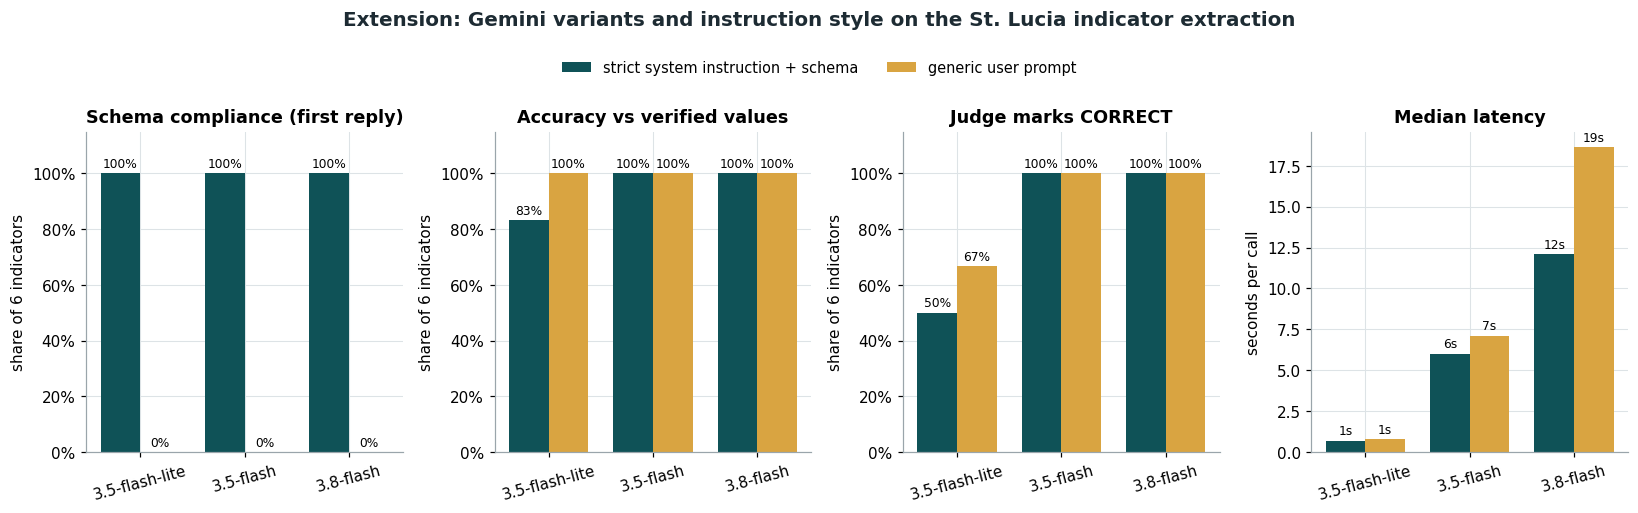

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# One look for every figure in this notebook: deep teal for the main series, a warm sand contrast,
# light grid behind the data, 300 dpi on save.
INK = {"main": "#0f5257", "contrast": "#d9a441", "muted": "#9aa5ab", "alert": "#b23a48", "text": "#1d2b33"}
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10,
                     "axes.edgecolor": INK["muted"], "axes.grid": True, "grid.color": "#dde3e6", "grid.linewidth": 0.7,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
                     "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight"})


def save_figure(fig, name: str) -> Path:
    target = DIRS.figures / name
    fig.savefig(target, dpi=300)
    return target


style_colour = {"strict_system": INK["main"], "generic_user": INK["contrast"]}
style_label = {"strict_system": "strict system instruction + schema", "generic_user": "generic user prompt"}
panels = [("schema_valid", "Schema compliance (first reply)", True), ("accuracy", "Accuracy vs verified values", True),
          ("judge_correct", "Judge marks CORRECT", True), ("median_latency_s", "Median latency", False)]
models_in_order = list(dict.fromkeys(bench_summary.model))
fig, axes = plt.subplots(1, 4, figsize=(15, 4.2))
width = 0.38
for ax, (metric, title, is_share) in zip(axes, panels):
    for j, style in enumerate(STYLES):
        part = bench_summary[bench_summary["style"] == style].set_index("model").reindex(models_in_order)
        xs = np.arange(len(models_in_order)) + (j - 0.5) * width
        bars = ax.bar(xs, part[metric], width, color=style_colour[style], label=style_label[style])
        ax.bar_label(bars, labels=[("" if pd.isna(v) else f"{v:.0%}" if is_share else f"{v:.0f}s") for v in part[metric]],
                     fontsize=8, padding=2)
    ax.set_xticks(range(len(models_in_order)), [short_model(m) for m in models_in_order], rotation=15)
    ax.set_title(title)
    if is_share:
        ax.set_ylim(0, 1.15)
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
        ax.set_ylabel("share of 6 indicators")
    else:
        ax.set_ylabel("seconds per call")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, fontsize=9.5, bbox_to_anchor=(0.5, 1.02))
fig.suptitle(f"Extension: Gemini variants and instruction style on the {CFG.country} indicator extraction",
             fontsize=13, fontweight="bold", color=INK["text"], y=1.10)
fig.tight_layout()
save_figure(fig, "extension_benchmark.png")
plt.show()

### Save benchmark outputs
> Per-answer rows and per-variant summaries are written as JSON under `artifacts/`.

In [30]:
dump_json("benchmark_runs.json", bench_frame.to_dict(orient="records"))
dump_json("benchmark_summary.json", {"design": {"task": "indicator extraction (Task 2.4 inputs)", "styles": STYLES,
                                                "models": {r: llm.models[r] for r in BENCH_ROLES},
                                                "judge": llm.models["judge"], "truth": truth},
                                     "summary": bench_summary.to_dict(orient="records"),
                                     "unavailable": unavailable,
                                     "judge_agreement_with_truth": round(float(bench_frame.judge_agrees.mean()), 3)})
dump_json("llm_call_ledger.json", llm.ledger)
print(f"LLM calls so far: {len(llm.ledger)} ({sum(not c['cached'] for c in llm.ledger)} live)")

LLM calls so far: 174 (0 live)


## Part 5 · Dashboard (Task 4)
### Task 4.1 · Wide indicator matrices to long format
> **Why this way:** the extraction is rebuilt as the IMF's wide table (series by period), which is the shape a human checks against the PDF, and then melted with `pd.melt` to one row per series and period for plotting. Empty cells are dropped, never drawn as 0 or -1.

In [31]:
# The IMF tables are wide: one row per series, one column per period. That layout is rebuilt here
# from the extraction (it is also what a human checks against the PDF page), then melted to long
# format, one row per series-period, which is what the plotting code needs. Empty cells become
# NaN and are dropped by melt's caller, never plotted as 0 or -1.
table_wide = series_long.pivot_table(index=["table", "series", "unit"], columns="period", values="value", aggfunc="first")
table_wide.to_csv(DIRS.json.parent / "indicator_tables_wide.csv")
tidy = pd.melt(table_wide.reset_index(), id_vars=["table", "series", "unit"], var_name="period", value_name="value")
tidy = tidy.dropna(subset=["value"])
projection_start = {t: g.loc[g.projection, "period"].min() for t, g in series_long.groupby("table")}
tidy["projection"] = [isinstance(projection_start.get(t), str) and p >= projection_start[t]
                      for t, p in zip(tidy.table, tidy.period)]
# Annual values sit at mid-year on the time axis; quarterly bank data at their own month.
tidy["date"] = pd.to_datetime(tidy.period.where(tidy.period.str.len() > 4, tidy.period + " Jul"), format="%Y %b")

# The three theme lenses are a wide matrix too (theme x lens): melted for a grouped bar chart.
lens_names = {"keyword_share": "keyword mentions", "nearest_share": "embedding nearest theme", "llm_share": "LLM primary label"}
theme_long = pd.melt(theme_frame, id_vars="theme", value_vars=list(lens_names), var_name="lens", value_name="share")
theme_long["lens"] = theme_long.lens.map(lens_names)
print(f"Wide tables {table_wide.shape} -> long {tidy.shape}; themes {theme_frame.shape} -> long {theme_long.shape}")
tidy.head(8)

Wide tables (12, 18) -> long (103, 7); themes (7, 8) -> long (21, 3)


,table,series,unit,period,value,projection,date
7,Table 5,Liquid Assets/Total Assets,percent,2018 Dec,39.4,False,2018-12-01
8,Table 5,Nonperforming loans to total gross loans,percent,2018 Dec,10.0,False,2018-12-01
9,Table 5,Regulatory Tier 1 capital to risk-weighted assets,percent,2018 Dec,13.2,False,2018-12-01
10,Table 5,Regulatory capital to risk-weighted assets (CAR),percent,2018 Dec,19.1,False,2018-12-01
11,Table 5,Return on Avg Assets,percent,2018 Dec,1.9,False,2018-12-01
12,Table 1,"Consumer prices, period average",percent change,2019,0.5,False,2019-07-01
13,Table 1,Credit to private sector (nominal),percent change,2019,-1.9,False,2019-07-01
14,Table 1,Current account balance,percent of GDP,2019,5.5,False,2019-07-01


### Task 4.2 · One function per panel
> **Why this way:** each chart is one function with a one-line question in its docstring, so the dashboard and the single-panel files for the report are drawn by the same code and cannot drift apart.

In [32]:
import textwrap

import matplotlib.dates as mdates


def series_of(name_part: str, table: str = "Table 1") -> pd.DataFrame:
    part = tidy[(tidy.table == table) & tidy.series.str.contains(name_part, case=False, regex=False)]
    return part.sort_values("date")


def shade_projection(ax, table: str = "Table 1"):
    start = projection_start.get(table)
    if isinstance(start, str):
        ax.axvspan(pd.Timestamp(f"{start[:4]}-01-01"), tidy.date.max() + pd.Timedelta(days=120),
                   color=INK["muted"], alpha=0.12, lw=0)
        ax.text(pd.Timestamp(f"{start[:4]}-01-01"), 0.97, " IMF projection", transform=ax.get_xaxis_transform(),
                va="top", fontsize=8, color=INK["text"])


def panel_macro(ax):
    """Growth, inflation and private credit: the recovery and the cooling the staff projects."""
    for name, colour, label in (("Real GDP", INK["main"], "Real GDP growth"),
                                ("Consumer prices", INK["alert"], "CPI inflation (period average)"),
                                ("Credit to private sector", INK["contrast"], "Private credit growth (nominal)")):
        s = series_of(name)
        ax.plot(s.date, s.value, marker="o", ms=3.5, lw=1.8, color=colour, label=label)
    shade_projection(ax)
    ax.axhline(0, color=INK["text"], lw=0.8)
    ax.set_title("Recovery and normalisation, 2019-2028")
    ax.set_ylabel("percent change, year on year")
    ax.legend(loc="lower right", fontsize=8)


def panel_debt(ax):
    """Public debt against the ECCU regional ceiling that staff says will not be met on current policies."""
    s = series_of("public sector debt")
    ax.fill_between(s.date, s.value, color=INK["main"], alpha=0.18)
    ax.plot(s.date, s.value, color=INK["main"], lw=2, marker="o", ms=3.5, label="Total public sector debt")
    ax.axhline(60, color=INK["alert"], ls="--", lw=1.4, label="ECCU ceiling: 60% of GDP by 2035")
    shade_projection(ax)
    last = s.iloc[-1]
    ax.annotate(f"{last.value:.1f}% in {last.period}", (last.date, last.value), xytext=(-70, 12),
                textcoords="offset points", fontsize=8, arrowprops={"arrowstyle": "-", "color": INK["muted"]})
    ax.set_ylim(0, max(100, s.value.max() + 10))
    ax.set_title("Public debt stays well above the regional ceiling")
    ax.set_ylabel("percent of GDP")
    ax.legend(loc="lower left", fontsize=8)


def panel_banks(ax):
    """Capital ratios against the NPL ratio, quarter by quarter, from the banking table."""
    for name, colour, label, style in (("(CAR)", INK["main"], "Capital to RWA (CAR)", "-"),
                                       ("Tier 1", INK["main"], "Tier 1 capital to RWA", ":"),
                                       ("Nonperforming", INK["alert"], "NPLs to gross loans", "-")):
        s = series_of(name, "Table 5")
        ax.plot(s.date, s.value, ls=style, marker="o", ms=3.5, lw=1.8, color=colour, label=label)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=12))      # ticks on the December readings
    ax.xaxis.set_major_formatter(mdates.DateFormatter("Dec %Y"))
    ax.set_xlabel("end of period (2022 also quarterly: Mar, Jun, Sep)")
    ax.set_title("Banks: NPLs rose while capital ratios held")
    ax.set_ylabel("percent")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)


def panel_credit_npl(ax):
    """Credit growth in a year against the NPL ratio at its end: does lending pick up as loans sour?"""
    credit = series_of("Credit to private sector")
    credit = pd.Series(credit.value.values, index=credit.period.str[:4])
    npl = series_of("Nonperforming", "Table 5")
    npl = npl[npl.period.str.endswith("Dec")]
    npl = pd.Series(npl.value.values, index=npl.period.str[:4])
    years = sorted(set(credit.index) & set(npl.index))
    ax.plot(credit[years], npl[years], color=INK["muted"], lw=1, zorder=1)
    ax.scatter(credit[years], npl[years], s=70, color=INK["contrast"], edgecolor=INK["text"], zorder=2)
    for y in years:
        ax.annotate(y, (credit[y], npl[y]), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
    ax.set_title("Private credit growth vs NPL ratio (year end)")
    ax.set_xlabel("private credit growth, percent")
    ax.set_ylabel("NPLs, percent of gross loans")


def panel_themes(ax):
    """Thematic density: share of attention per theme, measured three independent ways."""
    order = theme_frame.sort_values("llm_share").theme.tolist()
    lenses = list(lens_names.values())
    colours = [INK["muted"], INK["contrast"], INK["main"]]
    height = 0.26
    for j, (lens, colour) in enumerate(zip(lenses, colours)):
        part = theme_long[theme_long.lens == lens].set_index("theme").reindex(order)
        ax.barh(np.arange(len(order)) + (j - 1) * height, part.share, height, color=colour, label=lens)
    ax.set_yticks(range(len(order)), order)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("share of all theme hits")
    ax.set_title("Thematic density across the 7 financial themes")
    ax.legend(loc="lower right", fontsize=8)


def panel_rag(ax):
    """Model diagnostic: share of claims the judge could not find in the report, per question."""
    wide = rag_frame.pivot(index="qid", columns="kind", values="unsupported_share")
    wide = wide.reindex([q for q, *_ in RAG_QUESTIONS])
    ys = np.arange(len(wide))
    ax.hlines(ys, wide.rag, wide.closed_book, color=INK["muted"], lw=1.2)
    ax.scatter(wide.closed_book, ys, s=45, color=INK["alert"], label="closed book (no retrieval)", zorder=2)
    ax.scatter(wide.rag, ys, s=45, color=INK["main"], label="RAG with FAISS top-5", zorder=3)
    ax.set_yticks(ys, wide.index)
    ax.invert_yaxis()
    ax.set_xlim(-0.03, 1.03)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("claims unsupported or contradicted (judge)")
    ax.set_title("Retrieval cuts unsupported claims")
    ax.legend(loc="upper right", fontsize=8)


def panel_brief(ax):
    """Executive panel: the verified indicator JSON with periods and pages, and the brief's verdict."""
    ax.axis("off")
    names = {"gdp_growth_forecast_pct": "Real GDP growth forecast", "headline_inflation_rate_pct": "Headline inflation",
             "central_bank_policy_rate_pct": "ECCB policy rate", "non_performing_loan_ratio": "Bank NPL ratio",
             "unemployment_rate_pct": "Unemployment rate", "tier_1_capital_ratio": "Bank Tier 1 capital ratio"}
    lines = []
    for r in indicator_frame.itertuples():
        shown = "not reported" if r.value is None or pd.isna(r.value) else f"{r.value:.1f}%"
        page = "" if r.page is None or pd.isna(r.page) else f", PDF p.{int(r.page)}"
        lines.append(f"{names[r.field]:<27}{shown:>8}   ({r.period}{page})")
    ax.text(0.0, 1.0, f"{CFG.country}: {CFG.report_id}", fontsize=13, fontweight="bold", color=INK["text"],
            va="top", transform=ax.transAxes)
    ax.text(0.0, 0.84, "\n".join(lines), family="monospace", fontsize=9.2, va="top", transform=ax.transAxes)
    verdict = textwrap.fill(brief.overall_assessment, 70)
    heads = "\n".join(textwrap.fill(f"[{p.risk_level}] {p.headline}", 70, subsequent_indent="   ")
                      for p in brief.points[:4])
    ax.text(0.52, 0.84, "Overall assessment\n", fontsize=10, fontweight="bold", va="top", transform=ax.transAxes)
    ax.text(0.52, 0.76, verdict + "\n\n" + heads, fontsize=8.8, va="top", transform=ax.transAxes, color=INK["text"])
    ax.text(0.0, 0.08, "Indicators verified against the quoted passage in code\nand by hand against the PDF page. "
            "Shaded chart areas are IMF projections.", fontsize=7.8, color=INK["muted"], va="bottom", transform=ax.transAxes)


PANELS = {"macro_path": panel_macro, "public_debt": panel_debt, "bank_soundness": panel_banks,
          "credit_vs_npl": panel_credit_npl, "theme_density": panel_themes, "rag_diagnostic": panel_rag}

### Task 4.3 · Dashboard (300 dpi) and one file per panel
> The full dashboard and each panel on its own canvas are saved at 300 dpi under `artifacts/figures/`.

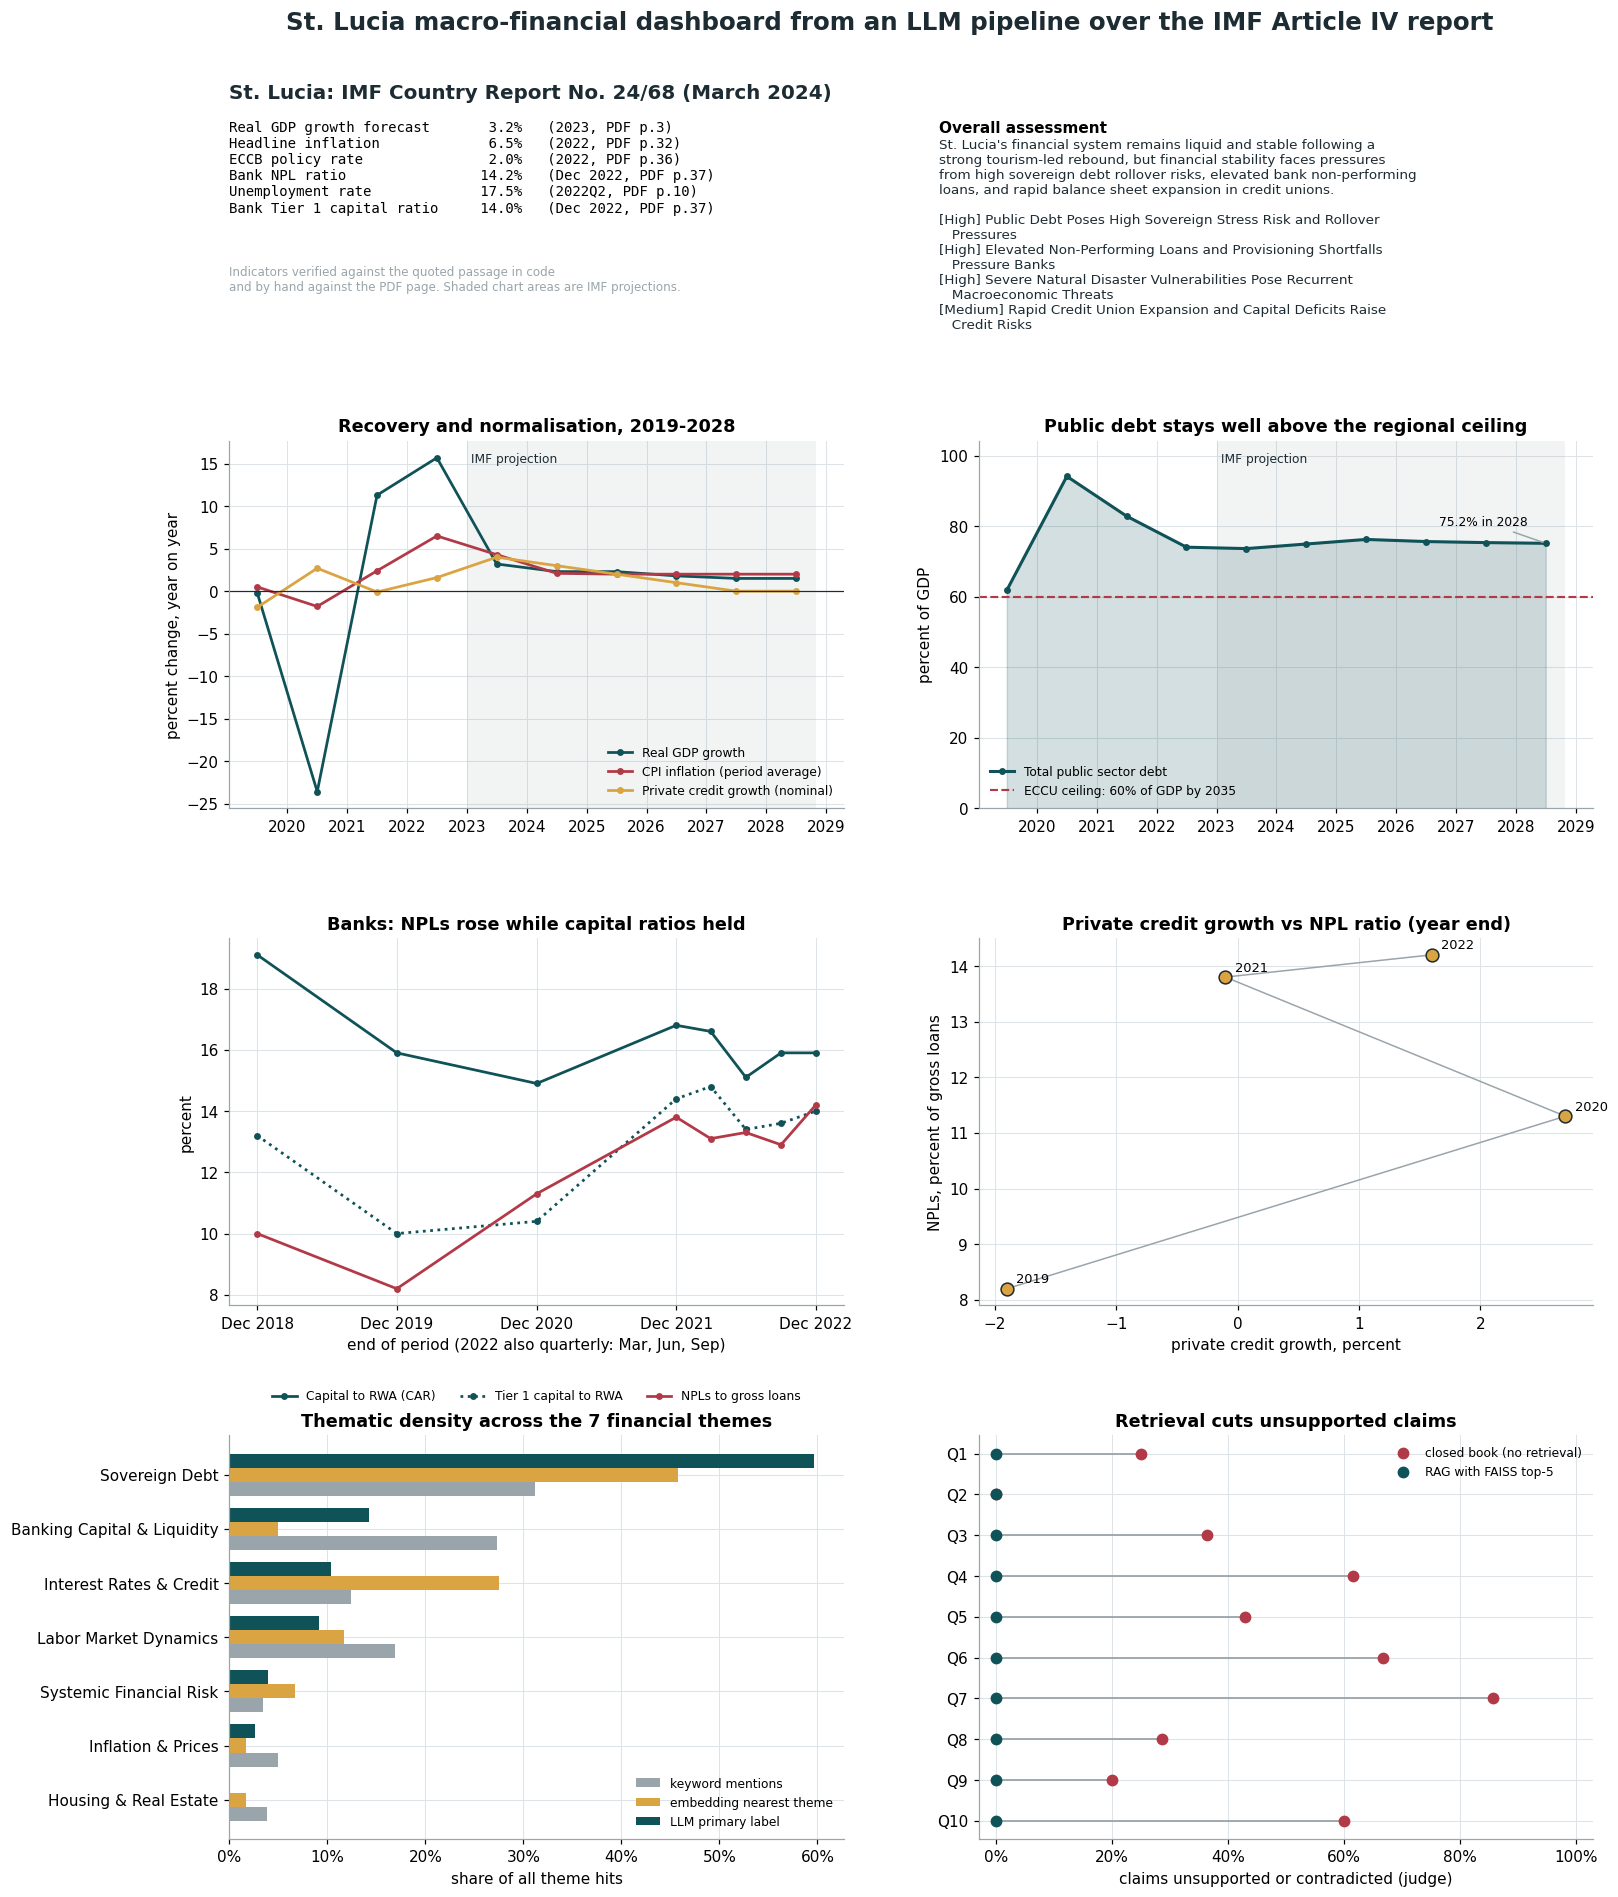

8 figures at 300 dpi: ['dashboard.png', 'extension_benchmark.png', 'fig_bank_soundness.png', 'fig_credit_vs_npl.png', 'fig_macro_path.png', 'fig_public_debt.png', 'fig_rag_diagnostic.png', 'fig_theme_density.png']


In [33]:
fig = plt.figure(figsize=(16, 19))
grid = fig.add_gridspec(4, 2, height_ratios=[0.62, 1, 1, 1.1], hspace=0.38, wspace=0.22, top=0.95)
panel_brief(fig.add_subplot(grid[0, :]))
for slot, draw in zip([(1, 0), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1)], PANELS.values()):
    draw(fig.add_subplot(grid[slot]))
fig.suptitle(f"{CFG.country} macro-financial dashboard from an LLM pipeline over the IMF Article IV report",
             fontsize=16, fontweight="bold", color=INK["text"], y=0.985)
save_figure(fig, "dashboard.png")
plt.show()

# Separate files for the report, each panel on its own canvas
for name, draw in PANELS.items():
    single, ax = plt.subplots(figsize=(7.5, 4.6))
    draw(ax)
    single.tight_layout()
    save_figure(single, f"fig_{name}.png")
    plt.close(single)
saved = sorted(p.name for p in DIRS.figures.glob("*.png"))
print(f"{len(saved)} figures at 300 dpi:", saved)

## Report evidence
### Full prompts and the numbers I checked by hand
> **Why this way:** every prompt quoted in the report is printed here in full, and every number I checked by hand is found again on its PDF page, so the report can be traced to this notebook's outputs.

In [34]:
REPORT_PROMPTS = {"Section summary": DIGEST_SYSTEM, "Executive brief": BRIEF_SYSTEM, "Summary judge": JUDGE_SYSTEM,
                  "Indicator extraction": READ_SYSTEM, "RAG answer": RAG_SYSTEM, "RAG judge": RAG_JUDGE,
                  "Benchmark, plain prompt": GENERIC_TEMPLATE}
for label, text in REPORT_PROMPTS.items():
    print(f"--- {label} ---\n{text}\n")

# Values the report quotes from my own reading of the PDF, found again on their page
HAND_CHECKS = [("EC$ peg", r"EC\$ ?2\.70"),
               ("ECCB policy rate, Table 4 (OCR)", r"ECCB policy rate.{0,40}"),
               ("Unemployment, Table 1", r"Unemployment rate.{0,60}?21\.9"),
               ("Unemployment, latest in the text", r"17\.5 percent in 2022"),
               ("Inflation, staff appraisal", r"[Ii]nflation.{0,30}?6\.4 percent"),
               ("Credit union capital bill", r"12 percent of assets")]
flat_pages = [" ".join(page.split()) for page in text_pages]
evidence = []
for label, pattern in HAND_CHECKS:
    hit = next(((n + 1, page, m) for n, page in enumerate(flat_pages) for m in [re.search(pattern, page)] if m), None)
    evidence.append({"check": label, "pdf_page": hit[0] if hit else None,
                     "text": hit[1][max(0, hit[2].start() - 60):hit[2].end() + 40] if hit else "not found"})
pd.set_option("display.max_colwidth", 140)
pd.DataFrame(evidence)

--- Section summary ---
You are a macro-financial analyst summarising one section of an IMF Article IV staff report on St. Lucia for a central bank board. Use only facts stated in the section. Lead with the main finding, then the risk or policy advice. Quote numbers exactly as printed with their unit and year. Every sentence must carry a specific fact from the section: no generic closing lines such as 'significant risks remain'. Attribute recommendations exactly as the section links them (what is advised, for what purpose). No preamble, no bullet points, no outside knowledge.

--- Executive brief ---
You write the executive summary of an IMF staff report for a financial stability committee. Cover the whole report: growth, fiscal and debt risks, the banking and credit union sector, and the main external and climate risks. Every point must be traceable to the section ids given. Rate risk_level by the report's own language (e.g. 'elevated', 'high', 'contained'). Keep the current position 

,check,pdf_page,text
0,EC$ peg,57,ed to the U.S. dollar under a currency board arrangement at EC$2.70 per U.S. dollar. St. Lucia has accepted
1,"ECCB policy rate, Table 4 (OCR)",36,32.4 32.4 32.4 324 324 Interest Rates (Percent Per Year) 1/ ECCB policy rate 6.5 2.00 2.00 2.00 we we a we we we Time deposit rate 1.5 1...
2,"Unemployment, Table 1",6,gap (percent of potential GDP) 6.5 -19.3 -11.3 1.0 2.2 2.5 Unemployment rate (% annual average) 16.8 21.7 21.9 … … … Nominal GDP (EC$ m...
3,"Unemployment, latest in the text",10,", bringing unemployment down from 23 percent in 2021: Q2 to 17.5 percent in 2022Q2 (Figure 1). The recovery was fueled b"
4,"Inflation, staff appraisal",25,al deficits. GDP grew by an estimated 15.7 percent in 2022. Inflation was high at 6.4 percent with strong impulse from international
5,Credit union capital bill,23,including the raising of the capital requirement by 2 pp to 12 percent of assets and limiting the use of collateral as a
